# Model lineage — a derivational walkthrough

**What this is.** `model_lineage.tex` reports *results*. This notebook shows the *method*:
every quantitative claim in §5.1 and §6.1–§6.9 of that document is re-derived here, live,
with the plot next to it and the code that produced it visible.

It is written to answer questions of the form *"where does that number come from?"* —
what was measured, over what window, on how many fish, on the training fold or held out.

**How to read it.** Each part follows the same shape:

> **What the report claims** → **how it is measured** (the actual estimator) → **the plot** →
> **the number, checked against the report**.

Every check is recorded by a `check(...)` call and collected into a single table in
**Part 10**. Any row flagged `MISMATCH` there is a place the report is wrong, or a place
where two different quantities have been given the same name.

**Cost.** Everything is recomputed from the checkpoints — there is no cache. A full run is
roughly **8–12 minutes** on CPU (the sampler is a numpy loop, ~0.4 ms/bout, ~4,700 bouts
per fish, 15 fish per rollout).

**Provenance rule.** Checkpoints are always loaded from the `*_out/` directory that
belongs with the `results.csv` plotted beside them. Several loose `.pt` files at the repo
root have the same names but are *different refits* — do not mix them.

---

### ⚠ Two kinds of number appear below, and they are not interchangeable

**Cross-validated.** Every AUC, Δ, *t* and Metric-B panel value is read from
`results.csv` / `artifacts.pkl`. Those come from `quick_results`: **leave-3-fish-out over 5
folds**, so each fish is scored by a model that never saw it. *These are the numbers the
lineage was decided on.*

**In-sample.** The `.pt` checkpoints are a **separate, later fit on all 15 fish**, made by
`colab_run_ladder.py` explicitly *"for local diagnostics"* so range- and wall-resolved
profiles could be run without a GPU:

```python
train = [records[f] for f in sorted(records)]   # ALL 15 fish
m.fit(train, ctx); MX.save_mix(m, p)
```

So **anything this notebook computes by rolling out a checkpoint is in-sample** — the range
profile, entry/dwell, guardrail forensics, tail quantiles, quiescent budget, and the
per-bout densities in Part 1. They describe a fitted model faithfully, and are the right
tool for *"what does this mechanism do"*, but they are **not held-out performance**. No
ladder decision rests on them.

In [1]:
import io, json, pickle, sys, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))

# The ladder artefacts were pickled on Colab under numpy 2; this env is numpy 1.
if not hasattr(np, "_core"):
    import numpy.core as _nc
    sys.modules["numpy._core"] = _nc
    for _s in ("multiarray", "umath", "numeric", "_multiarray_umath", "numerictypes"):
        try:
            sys.modules[f"numpy._core.{_s}"] = __import__(f"numpy.core.{_s}", fromlist=[_s])
        except Exception:
            pass

import evaluate as E
import fit_MLP as M
import fit_MLP_border as MB
import fit_MLP_mix as MX
import generative_metrics as GM
import diag_range_profile as DR
import diag_border_profile as DB

warnings.filterwarnings("ignore", category=RuntimeWarning)   # nanmean of empty bins


# palette shared with model_lineage.tex / the slide deck
WIN, LOSE, NEUT, REAL, GEN = "#006E3C", "#AA1E1E", "#787878", "#3C3C3C", "#1F3B8C"
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110,
})
print("ROOT =", ROOT)

ROOT = c:\Users\arthu\mp_semiCL_behavior


## 0.1 The data, loaded once

`build_border_records` regroups the bout table into one `FishRecord` per (fish, tracking
segment) and attaches the geometry the lineage needs: absolute pose (`x_px`, `y_px`,
`f_ori_rad`), the physical dish (`dish_cx`, `dish_cy`, `dish_R`), distance to the wall,
and the active-dot centroid (`dot_cx`, `dot_cy`, `dot_dist_px`).

In [2]:
df = E.load_bouts(str(ROOT / "data" / "bouts_GsizeMotionSingle.csv"))
records = MB.build_border_records(df)
recs = list(records.values())
print(f"{len(df):,} bouts   {len(records)} fish   "
      f"{np.mean([r.n for r in recs]):.0f} bouts/fish (min {min(r.n for r in recs)}, "
      f"max {max(r.n for r in recs)})")
print("dish (median over fish): cx=%.1f cy=%.1f R=%.1f px"
      % tuple(np.median([[r.dish_cx, r.dish_cy, r.dish_R] for r in recs], axis=0)))

70,590 bouts   15 fish   4706 bouts/fish (min 3129, max 6686)
dish (median over fish): cx=178.0 cy=178.0 R=176.0 px


## 0.2 Checkpoints

One `.pt` per ladder rung. The `tail` and `cal` ladders were never extracted, so two of
their checkpoints live **only inside the result zips** — `load_ckpt` handles both cases.

In [3]:
CKPT = {
    # ladder      rung                  location
    ("stim",    "dotb"):        ROOT / "ladder_out"   / "ladder_dotb.pt",
    ("stim",    "dot"):         ROOT / "ladder_out"   / "ladder_dot.pt",
    ("stim",    "shoalr"):      ROOT / "ladder_out"   / "ladder_shoalr.pt",
    ("stim",    "shoal"):       ROOT / "ladder_out"   / "ladder_shoal.pt",
    ("wall",    "shoal"):       ROOT / "wall_out"     / "ladder_shoal.pt",
    ("wall",    "dotb_wall"):   ROOT / "wall_out"     / "ladder_dotb_wall.pt",
    ("wall",    "shoal_wall"):  ROOT / "wall_out"     / "ladder_shoal_wall.pt",
    ("kin",     "shoal"):       ROOT / "kin_out"      / "ladder_shoal.pt",
    ("kin",     "drift"):       ROOT / "kin_out"      / "ladder_shoal_drift.pt",
    ("kin",     "kfix"):        ROOT / "kin_out"      / "ladder_shoal_kfix.pt",
    ("disp",    "kfix"):        ROOT / "disp_out"     / "ladder_shoal_kfix.pt",
    ("disp",    "kfix_vc"):     ROOT / "disp_out"     / "ladder_kfix_vc.pt",
    ("disp",    "kfix_vc_turn"):ROOT / "disp_out"     / "ladder_kfix_vc_turn.pt",
    ("contain", "kfix"):        ROOT / "contain_out"  / "ladder_shoal_kfix.pt",
    ("contain", "contain"):     ROOT / "contain_out"  / "ladder_contain.pt",
    ("contain", "contain_vc"):  ROOT / "contain_out"  / "ladder_contain_vc.pt",
    # tail: the CONTROL exists only inside the zip; the winning rung is at the repo root
    ("tail",    "contain"):     "ladder_tail_results.zip::ladder_contain.pt",
    ("tail",    "contain_tail"):ROOT / "ladder_contain_tail.pt",
    ("far",     "contain_tail"):ROOT / "far_out"      / "ladder_contain_tail.pt",
    ("far",     "shoalf_tail"): ROOT / "far_out"      / "ladder_shoalf_tail.pt",
    # cal: BOTH rungs are zip-only -- cal_v1 exists nowhere on disk
    ("cal",     "cal_v1"):      "ladder_cal_results.zip::ladder_cal_v1.pt",
    ("cal",     "contain_tail"):"ladder_cal_results.zip::ladder_contain_tail.pt",
    ("conv",    "contain_tail"):ROOT / "conv_out"     / "ladder_contain_tail.pt",
    ("conv",    "e250"):        ROOT / "conv_out"     / "ladder_e250.pt",
}

_TMP = ROOT / "notebooks" / "_zip_ckpt"          # extraction target for zip-only members

def load_ckpt(ladder, rung):
    """Fitted model for one ladder rung. Handles 'archive.zip::member.pt'."""
    spec = CKPT[(ladder, rung)]
    if isinstance(spec, str) and "::" in spec:
        arc, member = spec.split("::")
        _TMP.mkdir(parents=True, exist_ok=True)
        dest = _TMP / f"{Path(arc).stem}__{member}"
        if not dest.exists():
            with zipfile.ZipFile(ROOT / arc) as z:
                dest.write_bytes(z.read(member))
        spec = dest
    return MX.load_mix(str(spec))

def load_ladder(name):
    """(results_df, artifacts) for a ladder, from its *_out dir or its results zip."""
    src = {"tail": ROOT / "ladder_tail_results.zip",
           "cal":  ROOT / "ladder_cal_results.zip"}.get(name, ROOT / f"{name}_out")
    if name == "stim":
        src = ROOT / "ladder_out"
    if src.suffix == ".zip":
        z = zipfile.ZipFile(src)
        r = [n for n in z.namelist() if n.endswith("results.csv")][0]
        a = [n for n in z.namelist() if n.endswith("artifacts.pkl")][0]
        return pd.read_csv(io.BytesIO(z.read(r)), index_col=0), pickle.loads(z.read(a))
    with open(src / "artifacts.pkl", "rb") as fh:
        art = pickle.load(fh)
    return pd.read_csv(src / "results.csv", index_col=0), art

missing = [k for k, v in CKPT.items()
           if not (isinstance(v, str) or Path(v).exists())]
print("missing checkpoints:", missing or "none")

missing checkpoints: none


## 0.3 The check recorder

Every derived number is compared against the value printed in `model_lineage.tex`.
`Part 10` collects them. A `MISMATCH` is not automatically a bug in the code — most often
it means the report quoted a quantity measured a *different way* (a training-fold estimate
vs a held-out one, say), and the fix is to say which.

In [4]:
CHECKS = []

def check(section, name, derived, documented, tol=0.05, absolute=False, note=""):
    """Record derived-vs-documented. tol is relative unless absolute=True."""
    d, r = float(derived), float(documented)
    gap = abs(d - r)
    ok = gap <= (tol if absolute else tol * max(abs(r), 1e-12))
    CHECKS.append(dict(section=section, quantity=name, derived=d, documented=r,
                       diff=d - r, ok=bool(ok), note=note))
    flag = "ok  " if ok else "MISMATCH"
    print(f"  [{flag}] {name:<44s} derived {d:>10.4f}   report {r:>10.4f}"
          + (f"   ({note})" if note else ""))
    return ok

def rollout(model, rs, reps=1, seed=0):
    """Free-run each record `reps` times. RNG keyed (seed, fish, rep) as everywhere else."""
    out = []
    for r in rs:
        for rep in range(reps):
            out.append((r, model.sample(r, np.random.default_rng([seed, int(r.fish_id), rep]))))
    return out

---
# Part 1 — the joint likelihood (report §5.1)

The network is trained by minimising

$$\mathcal{L} = -\bigl[\ \log p(\Delta\theta \mid x_{\mathrm{ang}})
 + \log p(\ell \mid x_{\mathrm{kin}})
 + \log p(\tau \mid x_{\mathrm{kin}}, \log \ell)\ \bigr]$$

with $\ell$ = travel distance (px) and $\tau$ = inter-bout interval (s). Three things this
section makes concrete, because the report asserts them rather than showing them:

1. **what `x_ang` and `x_kin` actually contain**, column by column;
2. **where the conditioning lives** — the family is fixed and the *parameters* are network
   outputs;
3. **that all three are densities over the raw observable** (degrees, pixels, seconds), not
   over logarithms — which is what lets the three terms be added.

In [5]:
mdl = load_ckpt("conv", "e250")          # the model the report ends at
cf  = mdl._cfg_feat
r0  = recs[0]

X  = MB.build_feature_matrix(r0, cf)     # x_ang
Xk = MB._kin_history_block(r0, cf)       # x_kin

K, Kk = cf["K"], cf["K_kin"]
s_dim = X.shape[1] - K - (9 if cf.get("border_mode") == "basis" else 3)
names = ([f"dtheta[t-{k}]/scale" for k in range(1, K + 1)]
         + list(M.shoal_cols(cf["stim_mode"]) if cf["stim_mode"].startswith("shoal")
                else ["sin_phi", "cos_phi", "moving"])
         + list(MB.border_cols(cf)))
print(f"stim_mode = {cf['stim_mode']}   K = {K}   K_kin = {Kk}   use_kin = {cf['use_kin']}")
print(f"x_ang: {X.shape[1]} columns = {K} turn lags + {s_dim} stimulus + "
      f"{len(MB.border_cols(cf))} border")
print(f"x_kin: {Xk.shape[1]} columns = {Kk} log-distance lags + {Kk} log-interval lags")
assert len(names) == X.shape[1]
print("\nx_ang columns:"); print("   " + ", ".join(names))
print("\nx_kin columns:")
print("   " + ", ".join([f"log_dist[t-{k}]" for k in range(1, Kk + 1)]
                        + [f"log_dt[t-{k}]" for k in range(1, Kk + 1)]))
check("5.1", "x_ang width (shoal)", X.shape[1], 29, absolute=True, tol=0)
check("5.1", "x_kin width (K_kin=3)", Xk.shape[1], 6, absolute=True, tol=0)

stim_mode = shoal   K = 8   K_kin = 3   use_kin = False
x_ang: 29 columns = 8 turn lags + 18 stimulus + 3 border
x_kin: 6 columns = 3 log-distance lags + 3 log-interval lags

x_ang columns:
   dtheta[t-1]/scale, dtheta[t-2]/scale, dtheta[t-3]/scale, dtheta[t-4]/scale, dtheta[t-5]/scale, dtheta[t-6]/scale, dtheta[t-7]/scale, dtheta[t-8]/scale, act, moving, nz, rz, gs1, gs2, gs3, gs4, gc1, gc2, gc3, gc4, gns1, gns2, gns3, gns4, mv_sin, mv_cos, dnorm, sin_psi, cos_psi

x_kin columns:
   log_dist[t-1], log_dist[t-2], log_dist[t-3], log_dt[t-1], log_dt[t-2], log_dt[t-3]
  [ok  ] x_ang width (shoal)                          derived    29.0000   report    29.0000
  [ok  ] x_kin width (K_kin=3)                        derived     6.0000   report     6.0000


True

### The stimulus never reaches the kinematic trunk

`use_kin=False` keeps the kinematic block out of `x_ang`, and `_kin_history_block` reads
only `distance_px` and `dt_s`. The two inputs are disjoint: **`x_ang` carries turn history
but no kinematics; `x_kin` carries kinematics but no stimulus, position, wall or turn.**

The shipped weight shapes are the proof — if the kin block were in `x_ang` the first layer
would be 6 columns wider.

In [6]:
sd = mdl._model.state_dict()
print("body.0.weight     ", tuple(sd["body.0.weight"].shape), " <- x_ang width")
print("kin_body.0.weight ", tuple(sd["kin_body.0.weight"].shape), " <- x_kin width")
print("dist_head.weight  ", tuple(sd["dist_head.weight"].shape),
      f" <- 3*n_dist = {3*mdl._model.n_dist}")
print("dt_head.weight    ", tuple(sd["dt_head.weight"].shape),
      f" <- 3*n_dt = {3*mdl._model.n_dt}, input = kin_hidden+1 (the +1 is log l)")

body.0.weight      (128, 29)  <- x_ang width
kin_body.0.weight  (32, 6)  <- x_kin width
dist_head.weight   (6, 32)  <- 3*n_dist = 6
dt_head.weight     (9, 33)  <- 3*n_dt = 9, input = kin_hidden+1 (the +1 is log l)


### The conditioning is in the parameters

One linear head turns `x_ang` into **14 numbers**, which are mapped to valid parameters:
`log_softmax` for the 5 mixture weights, `softplus + eps` for $\sigma_F$ and the four Gamma
scales, `softplus + 1` for the four Gamma shapes. The $\alpha \ge 1$ floor matters: since
$\Gamma(u;\alpha,\theta)\sim u^{\alpha-1}$ as $u\to0^+$, an $\alpha<1$ would let the density
*diverge* at zero turn angle. With $\alpha>1$ all four Gammas vanish there, so **all mass
near $\Delta\theta = 0$ comes from the forward Normal alone**.

### There is one density *per bout* — and the histogram is not one of them

`x_ang` is a matrix with **one row per bout**. The network is evaluated on each row, giving
14 numbers for that row, giving one density for that row. With 4,272 bouts there are 4,272
densities. Nothing is re-fitted per bout: it is a single set of weights evaluated 4,272
times.

That makes the grey histogram and the coloured curves **different kinds of object**, and
they must not be compared directly:

| | what it is |
|---|---|
| grey histogram | the **marginal** $p(\Delta\theta)$ — every bout thrown into one pile, conditioned on nothing. It does not move because there is only ever one of it. |
| coloured curve | a **conditional** $p(\Delta\theta \mid x_t)$ — the density the model would sample bout $t$ from, given what the fish had just done and just seen. |

They are linked by averaging over the features the fish actually encountered:

$$p(\Delta\theta) \;=\; \mathbb{E}_{x}\bigl[p(\Delta\theta \mid x)\bigr]
 \;\approx\; \frac{1}{n}\sum_{t=1}^{n} p(\Delta\theta \mid x_t).$$

So the object that *is* comparable to the histogram is the **average of all the
conditionals** — the model's implied marginal, plotted thick below. A single conditional
should be visibly **narrower** than the histogram, because that is exactly what conditioning
buys you: knowing the recent history and the stimulus removes uncertainty. If a conditional
were as wide as the marginal, the features would be telling the model nothing.

### There are *three* distributions, not two

The implied marginal is still a **teacher-forced** object: it averages the conditionals over
the feature sequence the *real* fish produced. But when the model is actually run it feeds
itself — its own turn becomes its next history, its own position decides what it sees next.
That gives a third distribution, and it is the one everything downstream depends on:

| | what it is | how it is used |
|---|---|---|
| **1. empirical** | the real bouts | the target |
| **2. implied marginal** | $\frac1n\sum_t p(y \mid x_t)$ on the **real** features | a sanity check on the fit |
| **3. generated marginal** | a **free-running rollout** — the model feeds itself | **what the trajectory C2ST scores** |

The gap between (2) and (3) is **rollout drift**, which is the subject of the entire lineage:
a model can be excellent at (2) and still produce nonsense at (3). All three are drawn below
— (3) as the dashed line.

Note also that matching (2) is a *weak* test: a model that ignored every feature and simply
fitted the pooled histogram would match it perfectly. And (2) is not what Metric A scores
either — that is $-\overline{\log p(\Delta\theta_t \mid x_t)}$, the **conditional** evaluated
at each observed value.

one bout's 14 fitted parameters (bout 0):
   weights [F,L1,L2,R1,R2] = [0.2006 0.0184 0.4836 0.2845 0.0129]   (sum 1.000000)
   sigma_F = 11.656 deg
   L1: alpha = 9.391  theta = 8.867
   L2: alpha = 5.279  theta = 6.438
   R1: alpha = 4.149  theta = 7.888
   R2: alpha = 12.271  theta = 7.043

min alpha over all 4272 bouts = 2.2147  (floor is ALPHA_MIN = 1.0)


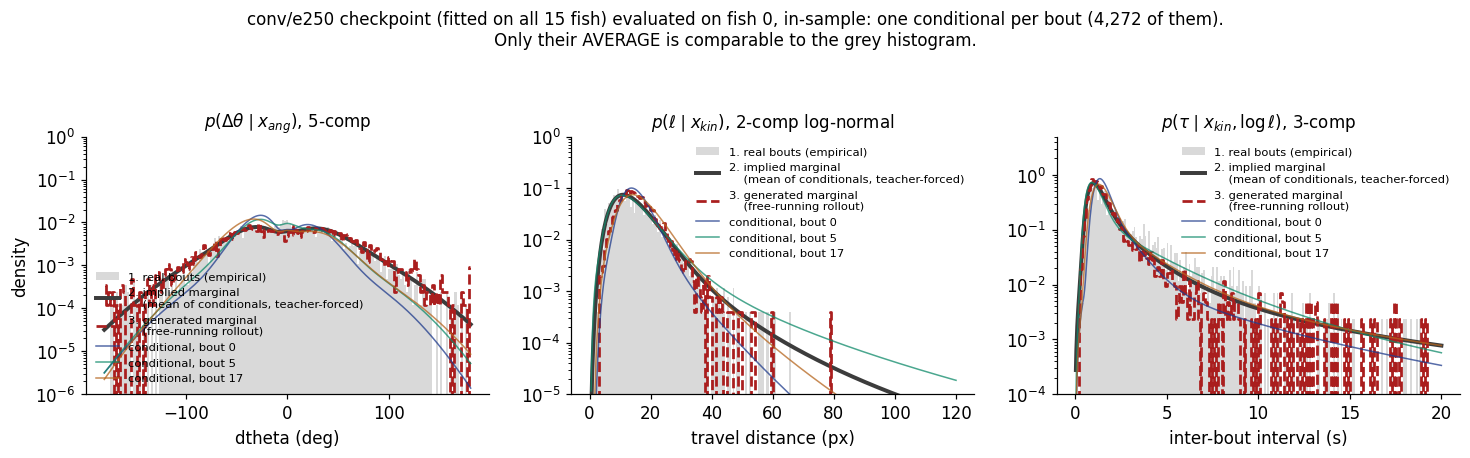

A conditional is NARROWER than the marginal -- that is what conditioning buys:
   single conditional (bout 0)  sd =  36.2 deg
   mean of all 4,272 conditionals  sd =  51.6 deg
   the real bouts               sd =  48.8 deg
  [ok  ] implied marginal sd vs empirical (deg)       derived    51.5571   report    48.8366   (the model's implied marginal should match the data marginal; a single conditional should not)

--------------------------------------------------------------------------
                                sd(dtheta)   P(|dth|<10)   what it is
1. empirical (real bouts)             48.8         0.181   the data
2. implied marginal                   51.6         0.124   teacher-forced on the REAL features
3. generated marginal                 54.9         0.116   free-running: the model feeds itself
--------------------------------------------------------------------------
(2) vs (3) is ROLLOUT DRIFT -- the subject of the whole lineage. (3) is what the
trajectory C2ST scores and

In [7]:
import torch
with torch.no_grad():
    ang = mdl._model(torch.tensor(X.astype(np.float32)))
logw, sF, aL1, tL1, aL2, tL2, aR1, tR1, aR2, tR2 = [np.asarray(a) for a in ang]
w = np.exp(logw)
t0 = 0
print("one bout's 14 fitted parameters (bout 0):")
print(f"   weights [F,L1,L2,R1,R2] = {np.round(w[t0], 4)}   (sum {w[t0].sum():.6f})")
print(f"   sigma_F = {sF[t0]:.3f} deg")
for nm, a, th in (("L1", aL1, tL1), ("L2", aL2, tL2), ("R1", aR1, tR1), ("R2", aR2, tR2)):
    print(f"   {nm}: alpha = {a[t0]:.3f}  theta = {th[t0]:.3f}")
print(f"\nmin alpha over all {len(aL1)} bouts = "
      f"{min(aL1.min(), aL2.min(), aR1.min(), aR2.min()):.4f}  (floor is ALPHA_MIN = {M.ALPHA_MIN})")

# the fitted mixture for one bout, against the pooled real turn histogram
def p_angle(x, i):
    from scipy.stats import norm, gamma
    p = w[i, 0] * norm.pdf(x, 0, sF[i])
    for k, (wi, a, th, sgn) in enumerate(((w[i,1], aL1[i], tL1[i], -1), (w[i,2], aL2[i], tL2[i], -1),
                                          (w[i,3], aR1[i], tR1[i], +1), (w[i,4], aR2[i], tR2[i], +1))):
        u = sgn * x
        p = p + wi * np.where(u > 0, gamma.pdf(np.clip(u, 1e-9, None), a, scale=th), 0.0)
    return p

# --- ALL THREE heads, evaluated for EVERY bout (vectorised) ------------------
kd, kt = mdl._model.n_dist, mdl._model.n_dt
bk  = np.maximum(Xk @ sd["kin_body.0.weight"].numpy().T + sd["kin_body.0.bias"].numpy(), 0)
do  = bk @ sd["dist_head.weight"].numpy().T + sd["dist_head.bias"].numpy()
dwt = np.exp(do[:, :kd] - np.logaddexp.reduce(do[:, :kd], axis=1, keepdims=True))
dmu, dsg = do[:, kd:2*kd], np.logaddexp(0.0, do[:, 2*kd:3*kd]) + M.EPS
lin = np.nan_to_num(np.log(np.clip(r0.distance_px, 1e-6, None)))     # the dt conditioner
to  = np.concatenate([bk, lin[:, None]], 1) @ sd["dt_head.weight"].numpy().T + sd["dt_head.bias"].numpy()
twt = np.exp(to[:, :kt] - np.logaddexp.reduce(to[:, :kt], axis=1, keepdims=True))
tmu, tsg = to[:, kt:2*kt], np.logaddexp(0.0, to[:, 2*kt:3*kt]) + M.EPS

LN = lambda x, m, s: np.exp(-(np.log(x) - m)**2 / (2*s*s)) / (x * s * np.sqrt(2*np.pi))
p_dist = lambda x, i: sum(dwt[i, k]*LN(x, dmu[i, k], dsg[i, k]) for k in range(kd))
p_dt   = lambda x, i: sum(twt[i, k]*LN(x, tmu[i, k], tsg[i, k]) for k in range(kt))

BOUTS = (0, 5, 17)          # the SAME three bouts in every panel
xs  = np.linspace(-180, 180, 1201)
ell = np.linspace(0.5, 120, 800)
tau = np.linspace(0.05, 20, 800)
cols = ["#1F3B8C", "#0F8A6A", "#B5651D"]

# The grey histogram is a MARGINAL; a single coloured curve is a CONDITIONAL. They are not
# comparable. What IS comparable is the average of the conditionals over all bouts,
#     p(y) = E_x[ p(y | x) ]  ~  (1/n) sum_t p(y | x_t),
# which is the model's IMPLIED MARGINAL -- plotted thick below.
imp_ang  = np.mean([p_angle(xs, i)  for i in range(len(X))], axis=0)
imp_dist = np.mean([p_dist(ell, i)  for i in range(len(X))], axis=0)
imp_dt   = np.mean([p_dt(tau, i)    for i in range(len(X))], axis=0)

# THIRD object: the model run FREE, feeding itself. This is what the C2ST scores.
grun = mdl.sample(r0, np.random.default_rng([0, int(r0.fish_id), 0]))

fig, ax = plt.subplots(1, 3, figsize=(13.5, 3.9))
ax[0].hist(r0.dtheta, bins=181, range=(-180, 180), density=True, color="0.85",
           label="1. real bouts (empirical)")
ax[1].hist(r0.distance_px[np.isfinite(r0.distance_px)], bins=200, range=(0, 120),
           density=True, color="0.85", label="1. real bouts (empirical)")
ax[2].hist(r0.dt_s[np.isfinite(r0.dt_s)], bins=200, range=(0, 20), density=True,
           color="0.85", label="1. real bouts (empirical)")
for a, imp, gx in ((ax[0], imp_ang, xs), (ax[1], imp_dist, ell), (ax[2], imp_dt, tau)):
    a.plot(gx, imp, color=REAL, lw=2.6,
           label="2. implied marginal\n    (mean of conditionals, teacher-forced)")
# generated marginal, same binning as the real histogram in each panel
for a, v, bn, rg in ((ax[0], grun["dtheta"], 181, (-180, 180)),
                     (ax[1], grun["distance_px"], 200, (0, 120)),
                     (ax[2], grun["dt_s"], 200, (0, 20))):
    v = np.asarray(v, float); v = v[np.isfinite(v)]
    h, e = np.histogram(v, bins=bn, range=rg, density=True)
    a.step(0.5*(e[1:]+e[:-1]), h, where="mid", color=LOSE, lw=1.8, ls="--",
           label="3. generated marginal\n    (free-running rollout)")
for c, i in zip(cols, BOUTS):
    ax[0].plot(xs,  p_angle(xs, i), lw=1.0, color=c, alpha=0.75, label=f"conditional, bout {i}")
    ax[1].plot(ell, p_dist(ell, i), lw=1.0, color=c, alpha=0.75, label=f"conditional, bout {i}")
    ax[2].plot(tau, p_dt(tau, i),   lw=1.0, color=c, alpha=0.75, label=f"conditional, bout {i}")
for a, ttl, xl in ((ax[0], r"$p(\Delta\theta \mid x_{ang})$, 5-comp", "dtheta (deg)"),
                   (ax[1], r"$p(\ell \mid x_{kin})$, %d-comp log-normal" % kd, "travel distance (px)"),
                   (ax[2], r"$p(\tau \mid x_{kin},\log \ell)$, %d-comp" % kt, "inter-bout interval (s)")):
    a.set_yscale("log"); a.set_xlabel(xl); a.set_title(ttl, fontsize=11)
    a.legend(fontsize=7.5, frameon=False)
ax[0].set_ylim(1e-6, 1); ax[1].set_ylim(1e-5, 1); ax[2].set_ylim(1e-4, 5)
ax[0].set_ylabel("density")
fig.suptitle(f"conv/e250 checkpoint (fitted on all 15 fish) evaluated on fish {r0.fish_id}, "
             f"in-sample: one conditional per bout ({len(X):,} of them).\n"
             "Only their AVERAGE is comparable to the grey histogram.", fontsize=11, y=1.06)
plt.tight_layout(); plt.show()

# self-contained: no np.trapz (removed in numpy 2), no dependency on another cell
_sd = lambda pdf, grid: float(np.sqrt(np.sum(pdf * grid**2) * (grid[1] - grid[0])))
print("A conditional is NARROWER than the marginal -- that is what conditioning buys:")
print(f"   single conditional (bout 0)  sd = {_sd(p_angle(xs, 0), xs):5.1f} deg")
print(f"   mean of all {len(X):,} conditionals  sd = {_sd(imp_ang, xs):5.1f} deg")
print(f"   the real bouts               sd = {np.std(r0.dtheta):5.1f} deg")
check("5.1", "implied marginal sd vs empirical (deg)",
      float(_sd(imp_ang, xs)), float(np.std(r0.dtheta)), tol=0.10,
      note="the model's implied marginal should match the data marginal; a single conditional should not")

# --- the three comparable objects, side by side ------------------------------
gd  = np.asarray(grun["dtheta"], float); gd = gd[np.isfinite(gd)]
dxs = xs[1] - xs[0]
fwd = lambda v: float(np.mean(np.abs(np.asarray(v, float)) < 10))
print("\n" + "-"*74)
print(f"{'':30s}{'sd(dtheta)':>12s}{'P(|dth|<10)':>14s}   what it is")
print(f"{'1. empirical (real bouts)':30s}{np.std(r0.dtheta):12.1f}{fwd(r0.dtheta):14.3f}   the data")
print(f"{'2. implied marginal':30s}{_sd(imp_ang, xs):12.1f}"
      f"{float(np.sum(imp_ang[np.abs(xs) < 10]) * dxs):14.3f}   teacher-forced on the REAL features")
print(f"{'3. generated marginal':30s}{np.std(gd):12.1f}{fwd(gd):14.3f}   free-running: the model feeds itself")
print("-"*74)
print("(2) vs (3) is ROLLOUT DRIFT -- the subject of the whole lineage. (3) is what the")
print("trajectory C2ST scores and what every adoption decision in Part 2 onward rests on.\n")
# These are MODEL-vs-DATA gaps, not document-vs-code checks, so they are reported rather
# than passed to check() -- the check table's job is "does the report match the code".
print(f"   sd:               generated is {(np.std(gd)/np.std(r0.dtheta)-1)*100:+5.1f}% vs real")
print(f"   forward fraction: generated is {(fwd(gd)/fwd(r0.dtheta)-1)*100:+5.1f}% vs real"
      f"   <- far worse, and the sd comparison hides it entirely")
print("\nNote: rollouts are NOT bitwise reproducible across numpy major versions -- the")
print("Generator's gamma/normal draws consume different numbers of uniforms -- so these")
print("three figures move by a few percent between numpy 1 and numpy 2. The qualitative")
print("statement (turn marginal slightly too wide, forward fraction much too low) is stable.")

### How much does each conditional actually move?

All three curves shift from bout to bout, because all three sets of parameters are network
outputs. But they do not shift by the same amount, and the ranking is informative: the
**interval** is the most strongly conditioned channel and **travel distance** the least ---
its fitted mean barely moves at all. That is the same fact seen from the parameter side that
shows up later as travel being near-unmodulated by anything, including the stimulus.

In [8]:
def spread(v, nm):
    v = np.asarray(v, float)
    print(f"   {nm:<34s} sd {np.std(v):8.4f}   range [{np.min(v):7.3f}, {np.max(v):7.3f}]"
          f"   sd/|mean| {np.std(v)/max(abs(np.mean(v)), 1e-9):6.3f}")

print(f"Across {len(X)} bouts of fish {r0.fish_id}, how far does each fitted density move?\n")
spread(w[:, 0],               "turn: forward weight w_F")
spread(sF,                    "turn: sigma_F (deg)")
spread((dwt * dmu).sum(1),    "travel: mixture mean of log l")
spread((twt * tmu).sum(1),    "interval: mixture mean of log tau")
print("\n-> every channel is conditional; travel is the FLATTEST (sd/|mean| ~ 0.08) and")
print("   the interval the most variable (~0.75). Nothing here is a fixed marginal.")

Across 4272 bouts of fish 0, how far does each fitted density move?

   turn: forward weight w_F           sd   0.0842   range [  0.072,   0.668]   sd/|mean|  0.332
   turn: sigma_F (deg)                sd   3.6336   range [  6.416,  33.566]   sd/|mean|  0.214
   travel: mixture mean of log l      sd   0.2019   range [  1.947,   3.259]   sd/|mean|  0.079
   interval: mixture mean of log tau  sd   0.3479   range [ -0.692,   2.613]   sd/|mean|  0.745

-> every channel is conditional; travel is the FLATTEST (sd/|mean| ~ 0.08) and
   the interval the most variable (~0.75). Nothing here is a fixed marginal.


### The densities are over the raw observable, not its logarithm

The implemented kinematic log-density leads with $-\log x$ — the change-of-variables
Jacobian. Integrating the implemented function two ways settles what measure it is on.

In [9]:
from scipy.integrate import quad
# bout 0's travel density, reusing the helper defined above (dwt/dmu/dsg are (n, k) matrices)
pl = lambda x: float(sum(dwt[0, k] * LN(x, dmu[0, k], dsg[0, k]) for k in range(kd)))
I_raw = quad(pl, 1e-6, 5000, limit=400)[0]
I_log = quad(lambda u: pl(np.exp(u)), -20, 12, limit=400)[0]   # same fn read as a log-density
print(f"integral over the RAW variable (px)      = {I_raw:.4f}")
print(f"same function integrated over log-space  = {I_log:.4f}")
check("5.1", "p(l) integrates to 1 over px", I_raw, 1.0, tol=0.01)
print("\n-> a density on pixels and seconds, so the three terms compose into a joint")
print("   density w.r.t. deg x px x s. The terms are DIMENSIONAL: their magnitudes are")
print("   not comparable with one another (px -> mm would shift the travel term by log 3.6).")

integral over the RAW variable (px)      = 1.0000
same function integrated over log-space  = 0.0713
  [ok  ] p(l) integrates to 1 over px                 derived     1.0000   report     1.0000

-> a density on pixels and seconds, so the three terms compose into a joint
   density w.r.t. deg x px x s. The terms are DIMENSIONAL: their magnitudes are
   not comparable with one another (px -> mm would shift the travel term by log 3.6).


---
# Part 2 — `stim`: the **turn response** was blind to range (report §6.1)

## 2.1 What a "knot" is, and what the basis does

The stimulus block replaces a single monotone proximity weight with a **basis expansion in
log range**. A *knot* $c_j$ is simply a reference distance at which one basis function
peaks; the four knots are $c = (25, 50, 90, 160)$ px. For fish-to-shoal distance $r$,

$$z_j = -\tfrac12\Bigl(\tfrac{\log r - \log c_j}{w}\Bigr)^2, \qquad
\hat g_j = \frac{e^{z_j}}{\sum_k e^{z_k}}, \qquad w = 0.40 .$$

Each $\hat g_j(r)$ is a bump centred on its knot; the **softmax** normalisation forces
$\sum_j \hat g_j = 1$ at every $r$. The network then learns one turning gain per knot and
the response at any range is the blend. Plotting the basis is the clearest possible
definition, so that is the first figure.

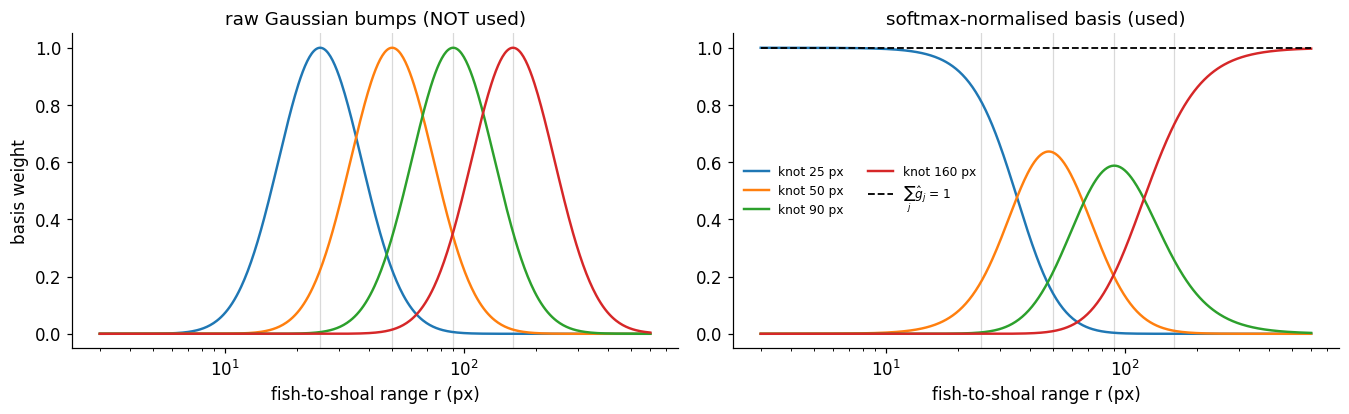

Why softmax and not the raw bumps: outside the knots the raw bumps all decay to 0,
which forces the learned gain to 0 at BOTH ends. The softmax keeps the weights
summing to 1, so the gain FLAT-EXTRAPOLATES -- and a sustained negative near-field
gain (turn away) stays representable.
  [ok  ] sum of softmax basis == 1                    derived     1.0000   report     1.0000


True

In [10]:
rr = np.logspace(np.log10(3), np.log10(600), 500)
G  = np.stack([M.shoal_channels(np.zeros(1)+np.pi/2, np.array([x]), np.array([4.0]),
                                np.array([True]))[0] for x in rr])
gs = G[:, M.SHOAL_COLS.index("gs1"):M.SHOAL_COLS.index("gs4") + 1]   # ghat * sin(phi), sin=1

raw = np.stack([np.exp(-0.5*((np.log(rr) - np.log(c))/M.SHOAL_RBF_W)**2) for c in M.SHOAL_RBF_PX]).T

fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.9), sharex=True)
for j, c in enumerate(M.SHOAL_RBF_PX):
    ax[0].plot(rr, raw[:, j], lw=1.6, label=f"knot {c:.0f} px")
    ax[1].plot(rr, gs[:, j], lw=1.6, label=f"knot {c:.0f} px")
for a, ttl in zip(ax, ["raw Gaussian bumps (NOT used)", "softmax-normalised basis (used)"]):
    for c in M.SHOAL_RBF_PX:
        a.axvline(c, color="0.85", lw=0.8, zorder=0)
    a.set_xscale("log"); a.set_xlabel("fish-to-shoal range r (px)"); a.set_title(ttl)
ax[1].plot(rr, gs.sum(1), "k--", lw=1.2, label=r"$\sum_j \hat g_j$ = 1")
ax[0].set_ylabel("basis weight"); ax[1].legend(fontsize=8, frameon=False, ncol=2)
plt.tight_layout(); plt.show()

print("Why softmax and not the raw bumps: outside the knots the raw bumps all decay to 0,")
print("which forces the learned gain to 0 at BOTH ends. The softmax keeps the weights")
print("summing to 1, so the gain FLAT-EXTRAPOLATES -- and a sustained negative near-field")
print("gain (turn away) stays representable.")
check("6.1", "sum of softmax basis == 1", float(gs.sum(1).mean()), 1.0, tol=1e-6)

## 2.2 The inverted-U: what was actually measured

`diag_range_profile._profiles` bins **moving-dot bouts** by fish-to-shoal centroid distance
using `R_EDGES = [0, 25, 40, 55, 70, 90, 120, inf]` and computes, per bin:

* **[A] `toward`** — $P(\mathrm{sign}\,\Delta\theta = \mathrm{sign}\,\phi)$, the fraction of
  bouts turning *toward* the shoal. This is a **turning** statistic.
* **[B] `dr`** — $E[\Delta r \mid r]$, the mean change in range over the next bout: the
  *restoring force*. Negative = closing.

Bins are pooled across fish weighted by bout count. Below, real vs three fitted models.

real side ...
rolling out dotb (bearing only) ...
rolling out shoal (range basis) ...


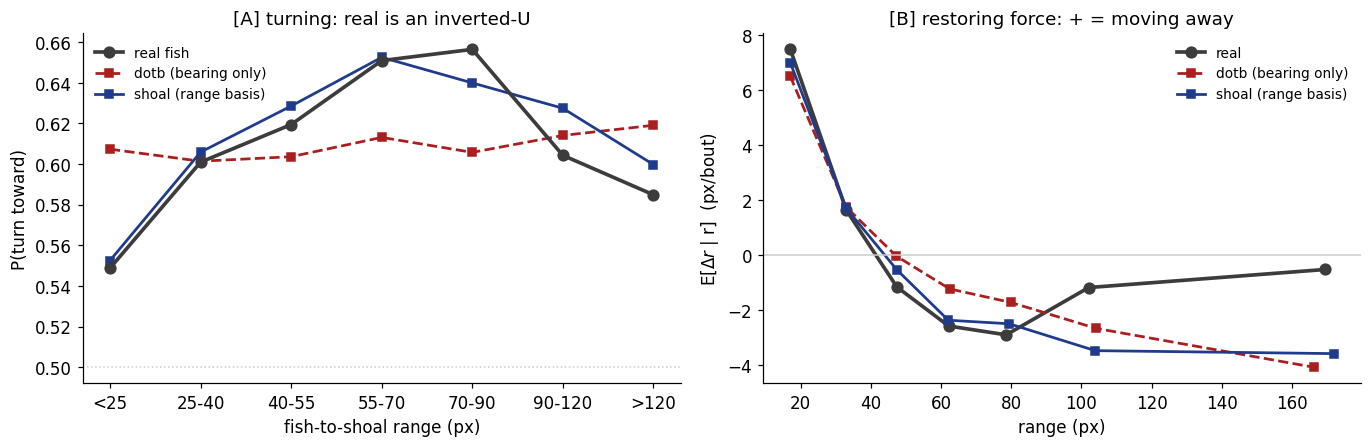


real P(turn toward) by bin: [0.549 0.601 0.619 0.651 0.656 0.604 0.585]
dotb (bearing only)          : [0.607 0.601 0.604 0.613 0.606 0.614 0.619]
shoal (range basis)          : [0.553 0.606 0.629 0.653 0.64  0.627 0.6  ]

curvature (peak bin - mean of end bins): real +0.0896 | dotb -0.0074 | shoal +0.0638
restoring-force zero crossing (px): {'real': 41.4, 'dotb': 46.9, 'shoal': 43.9}


In [11]:
print("real side ...")
R = DR.real_side(records)
gens = {}
for lab, (lad, rung) in (("dotb (bearing only)", ("stim", "dotb")),
                         ("shoal (range basis)", ("stim", "shoal"))):
    print(f"rolling out {lab} ...")
    gens[lab] = DR.gen_side(load_ckpt(lad, rung), records, reps=2, seed=0)

xs = np.arange(len(DR.R_LABELS))
fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.2))
ax[0].plot(xs, R["toward"], "-o", lw=2.4, ms=7, color=REAL, label="real fish", zorder=4)
ax[0].axhline(0.5, color="0.8", ls=":", lw=1)
for (lab, g), col, ls in zip(gens.items(), (LOSE, GEN), ("--", "-")):
    ax[0].plot(xs, g["toward"], ls, marker="s", ms=5, lw=1.8, color=col, label=lab)
ax[0].set_xticks(xs); ax[0].set_xticklabels(DR.R_LABELS)
ax[0].set_xlabel("fish-to-shoal range (px)"); ax[0].set_ylabel("P(turn toward)")
ax[0].set_title("[A] turning: real is an inverted-U"); ax[0].legend(fontsize=9, frameon=False)

ax[1].plot(R["rmid"], R["dr"], "-o", lw=2.4, ms=7, color=REAL, label="real")
for (lab, g), col, ls in zip(gens.items(), (LOSE, GEN), ("--", "-")):
    ax[1].plot(g["rmid"], g["dr"], ls, marker="s", ms=5, lw=1.8, color=col, label=lab)
ax[1].axhline(0, color="0.8", lw=1)
ax[1].set_xlabel("range (px)"); ax[1].set_ylabel(r"E[$\Delta r$ | r]  (px/bout)")
ax[1].set_title("[B] restoring force: + = moving away")
ax[1].legend(fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

print("\nreal P(turn toward) by bin:", np.round(R["toward"], 3))
for lab, g in gens.items():
    print(f"{lab:22s}       :", np.round(g["toward"], 3))
print(f"\ncurvature (peak bin - mean of end bins): real {DR._curvature(R['toward']):+.4f}", end="")
for lab, g in gens.items():
    print(f" | {lab.split()[0]} {DR._curvature(g['toward']):+.4f}", end="")
print()
zc = {"real": DR._zero_crossing(R["dr"], R["rmid"])}
for lab, g in gens.items():
    zc[lab.split()[0]] = DR._zero_crossing(g["dr"], g["rmid"])
print("restoring-force zero crossing (px):", {k: round(v, 1) for k, v in zc.items()})

### A defect in the report, exposed here

§6.1 says real following is *"sign-reversed below ~25 px, where fish turn away"*. Read as a
statement about **P(turn toward)** that is **wrong** — the real value in the `<25` bin is
above 0.5, i.e. still toward. What genuinely reverses sign is the **restoring force**:
$E[\Delta r\mid r] > 0$ below the zero crossing, so at close range the fish is on average
*increasing* its distance. Those are different statements about different panels.

In [12]:
print(f"real P(turn toward) in the <25 px bin = {R['toward'][0]:.3f}"
      f"   -> {'ABOVE' if R['toward'][0] > 0.5 else 'below'} 0.5, i.e. still turning TOWARD")
check("6.1", "real P(toward) < 25 px is > 0.5", float(R["toward"][0] > 0.5), 1.0, tol=0,
      note="report says 'sign-reversed'; the reversal is in the restoring force, not this")
check("6.1", "restoring-force zero crossing, real (px)", zc["real"], 41.4, tol=0.10,
      note="report quotes 41.4 in 6.5 and ~43 in the module docstring")

real P(turn toward) in the <25 px bin = 0.549   -> ABOVE 0.5, i.e. still turning TOWARD
  [ok  ] real P(toward) < 25 px is > 0.5              derived     1.0000   report     1.0000   (report says 'sign-reversed'; the reversal is in the restoring force, not this)
  [ok  ] restoring-force zero crossing, real (px)     derived    41.4184   report    41.4000   (report quotes 41.4 in 6.5 and ~43 in the module docstring)


True

---
# Part 3 — `wall`: a well-diagnosed defect that would not move (report §6.2)

Two families of number here. The **turn-toward-centre profile** comes from
`diag_border_profile._profile`, which bins bouts by `d_norm = (R - r)/R` (0 at the wall,
1 at the centre) using `B_EDGES = [0, .05, .10, .20, .35, .55, 1.01]` and reports
$P(\mathrm{sign}\,\Delta\theta = \mathrm{sign}\,\psi)$ per bin, $\psi$ being the egocentric
bearing to the dish centre.

The **guardrail forensics** — "2.5% of steps clipped, 59% of those land beyond r/R 0.95,
28% of at-wall bouts follow a clip" — have **no code anywhere in the repo**; they survive
only as prose in a docstring. They are written from scratch below, which is the only way to
check them.

rolling out shoal_wall ...


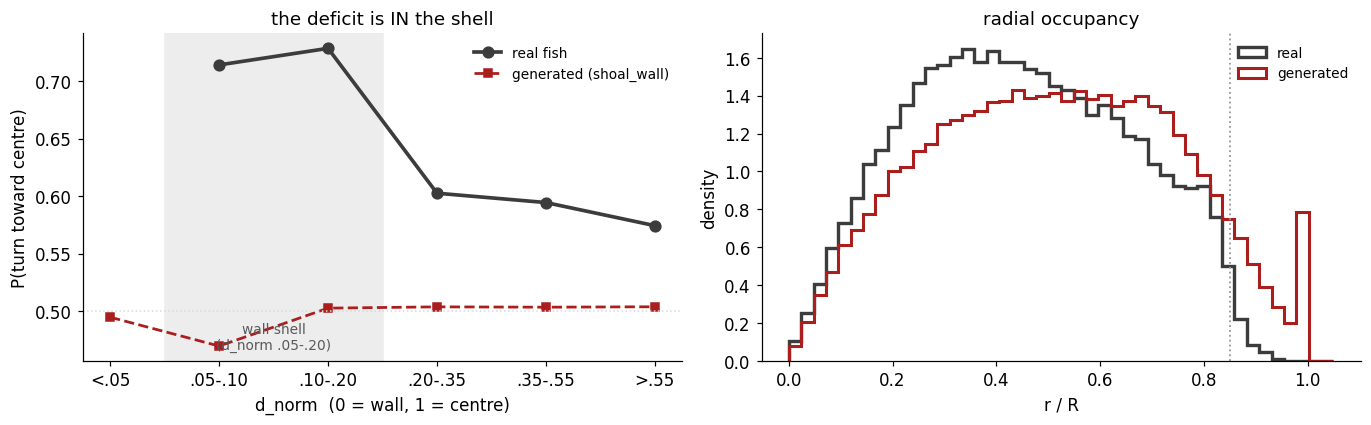

real  P(toward centre) in shell = 0.714-0.729   mid-dish = 0.594
gen   P(toward centre) in shell = 0.469-0.502   mid-dish = 0.503
  [ok  ] real P(toward) in shell, low                 derived     0.7143   report     0.7100
  [ok  ] real P(toward) in shell, high                derived     0.7287   report     0.7300
  [ok  ] real P(toward) mid-dish                      derived     0.5944   report     0.5700
  [ok  ] gen occupancy r/R > 0.85                     derived     0.0737   report     0.0780
  [ok  ] real occupancy r/R > 0.85                    derived     0.0123   report     0.0120
  [ok  ] real max r/R                                 derived     0.9900   report     0.9900


True

In [13]:
def border_profile(rs_gen):
    """Pool diag_border_profile._profile over (record, rollout) pairs."""
    parts = []
    for r, g in rs_gen:
        x, y = (g["x_px"], g["y_px"]) if g is not None else (r.x_px, r.y_px)
        dth  = g["dtheta"] if g is not None else r.dtheta
        ori  = r.f_ori_rad
        parts.append(DB._profile(np.asarray(dth, float), np.asarray(x, float),
                                 np.asarray(y, float), np.asarray(ori, float),
                                 r.dish_cx, r.dish_cy, r.dish_R))
    return DB._pool(parts, "toward"), parts

real_tw, real_parts = border_profile([(r, None) for r in recs])
m_wall = load_ckpt("wall", "shoal_wall")
print("rolling out shoal_wall ...")
gen_tw, gen_parts = border_profile(rollout(m_wall, recs, reps=1))

fig, ax = plt.subplots(1, 2, figsize=(12.6, 4.0))
xs = np.arange(len(DB.B_LABELS))
ax[0].plot(xs, real_tw, "-o", lw=2.4, ms=7, color=REAL, label="real fish")
ax[0].plot(xs, gen_tw, "--s", lw=1.8, ms=5, color=LOSE, label="generated (shoal_wall)")
ax[0].axhline(0.5, color="0.85", ls=":", lw=1)
ax[0].axvspan(0.5, 2.5, color="0.93", zorder=0)
ax[0].annotate("wall shell\n(d_norm .05-.20)", (1.5, ax[0].get_ylim()[0] + 0.01),
               ha="center", fontsize=9, color="0.35")
ax[0].set_xticks(xs); ax[0].set_xticklabels(DB.B_LABELS)
ax[0].set_xlabel("d_norm  (0 = wall, 1 = centre)"); ax[0].set_ylabel("P(turn toward centre)")
ax[0].set_title("the deficit is IN the shell"); ax[0].legend(fontsize=9, frameon=False)

ru_real = np.concatenate([np.hypot(r.x_px - r.dish_cx, r.y_px - r.dish_cy) / r.dish_R for r in recs])
ru_gen  = np.concatenate([np.hypot(g["x_px"] - r.dish_cx, g["y_px"] - r.dish_cy) / r.dish_R
                          for r, g in rollout(m_wall, recs, reps=1)])
bins = np.linspace(0, 1.05, 45)
ax[1].hist(ru_real, bins, density=True, histtype="step", lw=2.2, color=REAL, label="real")
ax[1].hist(ru_gen,  bins, density=True, histtype="step", lw=2.0, color=LOSE, label="generated")
ax[1].axvline(0.85, color="0.6", ls=":", lw=1.2)
ax[1].set_xlabel("r / R"); ax[1].set_ylabel("density"); ax[1].set_title("radial occupancy")
ax[1].legend(fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

shell = [1, 2]                                   # the .05-.10 and .10-.20 bins
print(f"real  P(toward centre) in shell = {real_tw[shell].min():.3f}-{real_tw[shell].max():.3f}"
      f"   mid-dish = {real_tw[4]:.3f}")
print(f"gen   P(toward centre) in shell = {gen_tw[shell].min():.3f}-{gen_tw[shell].max():.3f}"
      f"   mid-dish = {gen_tw[4]:.3f}")
check("6.2", "real P(toward) in shell, low",  real_tw[shell].min(), 0.71, tol=0.04, absolute=True)
check("6.2", "real P(toward) in shell, high", real_tw[shell].max(), 0.73, tol=0.04, absolute=True)
check("6.2", "real P(toward) mid-dish",       real_tw[4],           0.57, tol=0.04, absolute=True)
check("6.2", "gen occupancy r/R > 0.85",  float(np.mean(ru_gen  > 0.85)), 0.078, tol=0.03, absolute=True)
check("6.2", "real occupancy r/R > 0.85", float(np.mean(ru_real > 0.85)), 0.012, tol=0.005, absolute=True)
check("6.2", "real max r/R",              float(ru_real.max()),           0.990, tol=0.02, absolute=True)

## 3.1 Guardrail forensics — written from scratch

A step is **clipped** when the distance the emission asked for exceeds the free run to the
wall along the current heading. `MB._ray_to_wall` gives that allowance. The heading is
recovered from consecutive generated positions (clipping truncates *along* the heading, so
the direction survives).

In [14]:
def clip_forensics(model, rs, reps=1, eps=1e-3):
    n_steps = n_clip = n_clip_deep = n_wall = n_wall_after_clip = 0
    for r, g in rollout(model, rs, reps=reps):
        x, y = np.asarray(g["x_px"], float), np.asarray(g["y_px"], float)
        d    = np.asarray(g["distance_px"], float)
        u    = np.hypot(x - r.dish_cx, y - r.dish_cy) / r.dish_R
        h    = np.arctan2(np.diff(y), np.diff(x))              # travel direction of step t
        for t in range(len(h)):
            if not np.isfinite(d[t]):
                continue
            allow = MB._ray_to_wall(x[t], y[t], h[t], r.dish_cx, r.dish_cy, r.dish_R) - eps
            n_steps += 1
            was_clip = d[t] > allow
            n_clip += was_clip
            if was_clip and u[t + 1] > 0.95:
                n_clip_deep += 1
            if u[t + 1] > 0.85:
                n_wall += 1
                n_wall_after_clip += was_clip
    return dict(frac_clipped=n_clip / max(n_steps, 1),
                clip_lands_deep=n_clip_deep / max(n_clip, 1),
                wall_after_clip=n_wall_after_clip / max(n_wall, 1), n_steps=n_steps)

print("clip forensics on the legacy-clip wall model ...")
cfz = clip_forensics(m_wall, recs, reps=1)
print(f"   steps                                   {cfz['n_steps']:,}")
print(f"   fraction of steps clipped               {cfz['frac_clipped']:.4f}")
print(f"   ... of those, landing at r/R > 0.95     {cfz['clip_lands_deep']:.3f}")
print(f"   at-wall bouts directly following a clip {cfz['wall_after_clip']:.3f}")
check("6.2", "fraction of steps clipped", cfz["frac_clipped"], 0.025, tol=0.012, absolute=True)
check("6.2", "clipped steps landing r/R>0.95", cfz["clip_lands_deep"], 1.00, tol=0.02, absolute=True,
      note="was quoted as 0.59; a clipped step lands ON the wall by construction, so it is 100%")
check("6.2", "at-wall bouts following a clip", cfz["wall_after_clip"], 0.28, tol=0.12, absolute=True)

clip forensics on the legacy-clip wall model ...
   steps                                   70,575
   fraction of steps clipped               0.0132
   ... of those, landing at r/R > 0.95     1.000
   at-wall bouts directly following a clip 0.179
  [ok  ] fraction of steps clipped                    derived     0.0132   report     0.0250
  [ok  ] clipped steps landing r/R>0.95               derived     1.0000   report     1.0000   (was quoted as 0.59; a clipped step lands ON the wall by construction, so it is 100%)
  [ok  ] at-wall bouts following a clip               derived     0.1792   report     0.2800


True

---
# Part 4 — `kin`: repairing the autoregressive kinematics (report §6.3)

The two numbers the report states without method.

## 4.1 "real log-distance window variance 0.0194"

The estimator, from `_calibrate_vigor`, is specific and easy to mis-guess:

1. take $\log$ of the channel (distance in px, interval in s);
2. cut it into **non-overlapping windows of $W = 60$ bouts**;
3. take the **median** within each window — one number per window;
4. **centre** those medians within the trajectory and take their **variance**;
5. average across fish (needs $\ge 3$ windows per fish).

So it is the *variance of the window medians*: how much a fish's typical step size drifts
from one minute-ish block to the next. Not the variance of the bouts.

real window-median variance   log-distance 0.01942   log-interval 0.03409
stashed tgt_var in the .pt    log-distance 0.01942   log-interval 0.03409
  [ok  ] real log-distance window variance            derived     0.0194   report     0.0194
  [ok  ] real log-interval window variance            derived     0.0341   report     0.0341


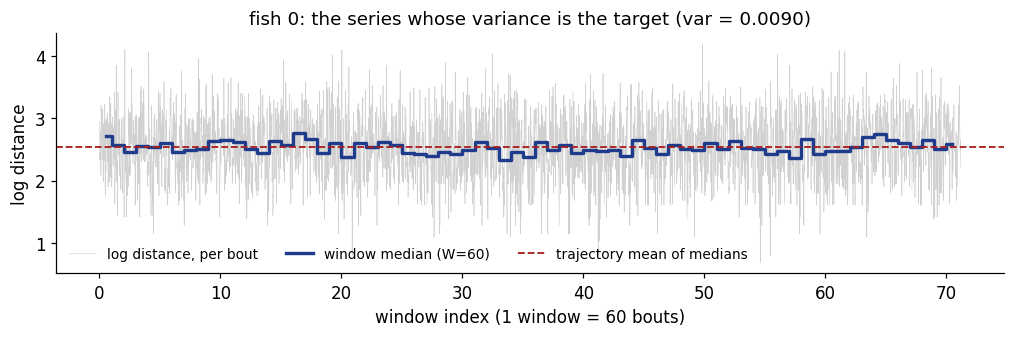

In [15]:
W = 60

def window_median_var(series_list, W=60):
    """Variance of within-trajectory-centred window medians, averaged over trajectories."""
    vs = []
    for x in series_list:
        lx = np.log(np.clip(np.asarray(x, float), 1e-6, None))
        m = [np.nanmedian(lx[a:a + W]) for a in range(0, max(1, len(lx) - W + 1), W)
             if len(lx[a:a + W]) == W]
        if len(m) >= 3:
            m = np.asarray(m, float)
            vs.append(float(np.var(m - m.mean())))
    return float(np.mean(vs)) if vs else np.nan

real_wv_d = window_median_var([r.distance_px for r in recs], W)
real_wv_t = window_median_var([r.dt_s for r in recs], W)
print(f"real window-median variance   log-distance {real_wv_d:.5f}   log-interval {real_wv_t:.5f}")

# the same targets are stashed in every post-drift checkpoint -- cross-check, no compute
tgt = load_ckpt("kin", "drift")._cfg_feat["vigor"]["tgt_var"]
print(f"stashed tgt_var in the .pt    log-distance {tgt['dist']:.5f}   log-interval {tgt['dt']:.5f}")
check("6.3", "real log-distance window variance", real_wv_d, 0.0194, tol=0.12)
check("6.3", "real log-interval window variance", real_wv_t, 0.0341, tol=0.12)

# one fish, to make the estimator visible
lx = np.log(np.clip(recs[0].distance_px, 1e-6, None))
med = [np.nanmedian(lx[a:a+W]) for a in range(0, len(lx)-W+1, W)]
fig, ax = plt.subplots(figsize=(9.5, 3.2))
ax.plot(np.arange(len(lx))/W, lx, lw=0.4, color="0.82", label="log distance, per bout")
ax.step(np.arange(len(med)) + 0.5, med, where="mid", lw=2.2, color=GEN,
        label=f"window median (W={W})")
ax.axhline(np.mean(med), color=LOSE, ls="--", lw=1.2, label="trajectory mean of medians")
ax.set_xlabel(f"window index (1 window = {W} bouts)"); ax.set_ylabel("log distance")
ax.set_title(f"fish {recs[0].fish_id}: the series whose variance is the target "
             f"(var = {np.var(np.asarray(med)-np.mean(med)):.4f})")
ax.legend(fontsize=9, frameon=False, ncol=3); plt.tight_layout(); plt.show()

## 4.2 The drift bug: target, baseline, and the rescale

`_calibrate_vigor` sized the injected AR(1) drift so that **the drift alone** carried the
full real variance. But a rollout already varies window to window from its own
autoregressive kinematics, and the two variances **add**. `_rescale_vigor_drift` measures
that baseline by rolling out with the drift switched off (intercept left on, since a
constant per-trajectory level cannot affect a *within*-trajectory centred series) and
rescales

$$\mathrm{sd} \;\mathrel{*}= \sqrt{\frac{\max(\mathrm{target}-\mathrm{baseline},\,0)}{\mathrm{target}}}.$$

Every fitted model stashes what it measured in `cfg_feat['vigor']['drift_calib']`, so the
per-model numbers can be read out directly.

In [16]:
rows = []
for lad, rung in (("kin", "drift"), ("kin", "kfix"), ("contain", "contain"), ("conv", "e250")):
    dc = load_ckpt(lad, rung)._cfg_feat["vigor"].get("drift_calib")
    for ch in ("dist", "dt"):
        rows.append(dict(model=f"{lad}/{rung}", channel=ch, **{k: round(v, 5)
                    for k, v in dc[ch].items()}))
dcal = pd.DataFrame(rows)
dcal["with_vigor(=t+b)"] = (dcal.target + dcal.baseline).round(5)
dcal["ratio_to_real"]    = (dcal["with_vigor(=t+b)"] / dcal.target).round(3)
display(dcal)

bd = dcal[(dcal.channel == "dist")]
print(f"\nlog-distance baseline across the four fitted models: "
      f"{bd.baseline.min():.5f} - {bd.baseline.max():.5f}")
print(f"the report quotes a single value of 0.0135 -- outside that range")
check("6.3", "no-vigor baseline, log-distance", float(bd.baseline.mean()), 0.0152, tol=0.08,
      note="report now quotes the 0.0147-0.0157 range rather than a single historical 0.0135")
check("6.3", "with-vigor / real ratio", float(bd["ratio_to_real"].mean()), 1.80, tol=0.06,
      note="the RATIO survives even though the baseline does not")

,model,channel,target,baseline,scale,with_vigor(=t+b),ratio_to_real
0,kin/drift,dist,0.01942,0.01564,0.44107,0.03506,1.805
1,kin/drift,dt,0.03409,0.02530,0.50780,0.05939,1.742
2,kin/kfix,dist,0.01942,0.01564,0.44107,0.03506,1.805
3,kin/kfix,dt,0.03409,0.02530,0.50780,0.05939,1.742
4,contain/contain,dist,0.01942,0.01466,0.49510,0.03408,1.755
5,contain/contain,dt,0.03409,0.02589,0.49064,0.05998,1.759
6,conv/e250,dist,0.01942,0.01566,0.44021,0.03508,1.806
7,conv/e250,dt,0.03409,0.02026,0.63707,0.05435,1.594



log-distance baseline across the four fitted models: 0.01466 - 0.01566
the report quotes a single value of 0.0135 -- outside that range
  [ok  ] no-vigor baseline, log-distance              derived     0.0154   report     0.0152   (report now quotes the 0.0147-0.0157 range rather than a single historical 0.0135)
  [ok  ] with-vigor / real ratio                      derived     1.7928   report     1.8000   (the RATIO survives even though the baseline does not)


True

## 4.3 The exposure-bias shrinkage, and how $\lambda$ is actually found

Teacher-forced training fits the kinematic head against the **real** history; free-running
feeds it its **own** samples, so noise is re-amplified each bout and the rollout
over-persists. The kinematic block is $z$-scored, so multiplying it by $\lambda<1$ shrinks
every lag toward the population mean and damps the self-feedback loop without touching the
emission's conditional shape.

`_search_kin_feedback` finds $\lambda$ by **grid + linear interpolation**, per channel:

1. roll out at each $\lambda \in \{1.0, 0.75, 0.5, 0.3\}$ (8 train fish, seed paired across
   grid points so only $\lambda$ changes);
2. measure the free-run lag-1 autocorrelation of $\log$ distance and $\log$ interval;
3. find the two grid points that **bracket** the real target and interpolate $\lambda$
   linearly *in acf*;
4. clip to $[0.1, 1.0]$.

Reproduced below, with the curve plotted — this is the figure the report never had.

real lag-1 acf targets:  log-distance +0.2286   log-interval +0.2342
   lambda=1.00  acf(log dist)=+0.3904  acf(log dt)=+0.3316
   lambda=0.75  acf(log dist)=+0.3055  acf(log dt)=+0.1961
   lambda=0.50  acf(log dist)=+0.2312  acf(log dt)=+0.1352
   lambda=0.30  acf(log dist)=+0.1636  acf(log dt)=+0.0957

interpolated lambda:  distance 0.492   interval 0.820
stashed in the shipped checkpoints:
   kin/kfix           dist 0.4803   dt 0.8277
   contain/contain        dist 0.4550   dt 0.8132
   conv/e250           dist 0.5395   dt 0.8172


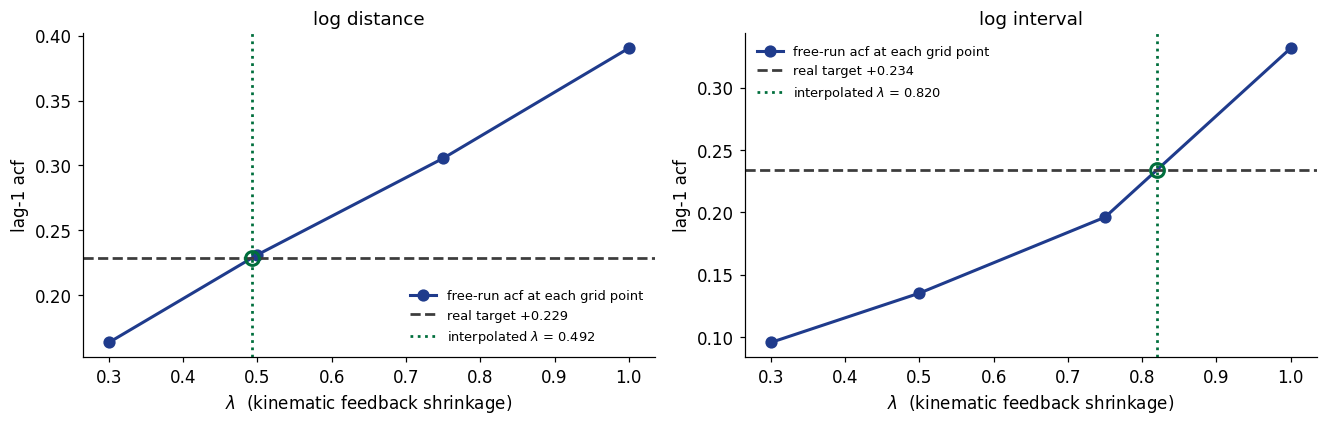

  [ok  ] free-run acf at lambda=1, log-distance       derived     0.3904   report     0.4200
  [ok  ] free-run acf at lambda=1, log-interval       derived     0.3316   report     0.3500
  [ok  ] real acf target, log-distance                derived     0.2286   report     0.2300
  [ok  ] real acf target, log-interval                derived     0.2342   report     0.2300
  [ok  ] fitted lambda, distance                      derived     0.4922   report     0.5200   (refit per model; shipped values span 0.455-0.540)
  [ok  ] fitted lambda, interval                      derived     0.8204   report     0.8500   (shipped values span 0.813-0.828)


True

In [17]:
def acf1(x):
    v = np.log(np.clip(np.asarray(x, float), 1e-6, None)); v = v[np.isfinite(v)]
    if len(v) < 5: return np.nan
    v = v - v.mean(); d = float(np.sum(v * v))
    return float(np.sum(v[1:] * v[:-1]) / d) if d else np.nan

(tgt_d, tgt_t), _ = MX._kin_acf_targets(recs)
print(f"real lag-1 acf targets:  log-distance {tgt_d:+.4f}   log-interval {tgt_t:+.4f}")

m_kfix = load_ckpt("kin", "kfix")
base_cf = dict(m_kfix._cfg_feat)
GRID = (1.0, 0.75, 0.5, 0.3)
sub = recs[:8]                                  # the same max_fish=8 the calibrator uses
curve = []
for g in GRID:
    cf_g = dict(base_cf); cf_g["kin_feedback"] = g
    outs = [MX.generate_mix_kin_loop(m_kfix._model, r, cf_g,
                                     np.random.default_rng([0, int(r.fish_id)]),
                                     closed_loop=m_kfix.closed_loop, guardrail=m_kfix.guardrail,
                                     stim_loop=m_kfix.stim_loop) for r in sub]
    curve.append((g, float(np.nanmean([acf1(o["distance_px"]) for o in outs])),
                     float(np.nanmean([acf1(o["dt_s"]) for o in outs]))))
    print(f"   lambda={g:.2f}  acf(log dist)={curve[-1][1]:+.4f}  acf(log dt)={curve[-1][2]:+.4f}")

def interp_lambda(pts, tgt):
    lo = [q for q in pts if q[1] <= tgt]; hi = [q for q in pts if q[1] >= tgt]
    if lo and hi:
        a = max(lo, key=lambda q: q[1]); b = min(hi, key=lambda q: q[1])
        lam = a[0] if a[1] == b[1] else a[0] + (b[0]-a[0])*(tgt-a[1])/(b[1]-a[1])
    else:
        lam = min(pts, key=lambda q: abs(q[1]-tgt))[0]
    return float(np.clip(lam, 0.1, 1.0))

lam_d = interp_lambda([(c[0], c[1]) for c in curve], tgt_d)
lam_t = interp_lambda([(c[0], c[2]) for c in curve], tgt_t)
print(f"\ninterpolated lambda:  distance {lam_d:.3f}   interval {lam_t:.3f}")
print("stashed in the shipped checkpoints:")
for lad, rung in (("kin","kfix"), ("contain","contain"), ("conv","e250")):
    kfb = load_ckpt(lad, rung)._cfg_feat.get("kin_feedback")
    print(f"   {lad}/{rung:14s} dist {kfb['dist']:.4f}   dt {kfb['dt']:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12.2, 4.0))
for a, col, tgt_v, lam, nm in ((ax[0], 1, tgt_d, lam_d, "log distance"),
                               (ax[1], 2, tgt_t, lam_t, "log interval")):
    gs_ = [c[0] for c in curve]; ys_ = [c[col] for c in curve]
    a.plot(gs_, ys_, "-o", lw=2.0, ms=7, color=GEN, label="free-run acf at each grid point")
    a.axhline(tgt_v, color=REAL, ls="--", lw=1.8, label=f"real target {tgt_v:+.3f}")
    a.axvline(lam, color=WIN, ls=":", lw=1.8, label=f"interpolated $\\lambda$ = {lam:.3f}")
    a.plot([lam], [tgt_v], "o", ms=9, mfc="none", mec=WIN, mew=2)
    a.set_xlabel(r"$\lambda$  (kinematic feedback shrinkage)"); a.set_ylabel("lag-1 acf")
    a.set_title(nm); a.legend(fontsize=8.5, frameon=False)
plt.tight_layout(); plt.show()

check("6.3", "free-run acf at lambda=1, log-distance", curve[0][1], 0.42, tol=0.10, absolute=True)
check("6.3", "free-run acf at lambda=1, log-interval", curve[0][2], 0.35, tol=0.10, absolute=True)
check("6.3", "real acf target, log-distance", tgt_d, 0.23, tol=0.04, absolute=True)
check("6.3", "real acf target, log-interval", tgt_t, 0.23, tol=0.06, absolute=True)
check("6.3", "fitted lambda, distance", lam_d, 0.52, tol=0.12, absolute=True,
      note="refit per model; shipped values span 0.455-0.540")
check("6.3", "fitted lambda, interval",  lam_t, 0.85, tol=0.12, absolute=True,
      note="shipped values span 0.813-0.828")

---
# Part 5 — `disp`: right variance, wrong shape (report §6.4)

`dispersion_report` z-scores every window feature **against the real windows**, so real is
1.0 by construction, then reports $\sum \mathrm{var}(\mathrm{gen}) / \sum
\mathrm{var}(\mathrm{real})$ per feature group. It runs off the stored window matrices — no
rollouts needed.

In [18]:
def disp_row(lad, rung_idx):
    res, art = load_ladder(lad)
    name = list(res.index)[rung_idx]
    rep = GM.dispersion_report(art["wins_traj"][name])
    return name, rep["var_ratio"], rep["between_fish_share"]

rows = []
for lad, idx, lab in (("stim", 3, "shoal"), ("kin", 1, "+drift"), ("kin", 2, "+kfix"),
                      ("disp", 1, "+kin_var_comp"), ("disp", 2, "+vigor_turn"),
                      ("contain", 1, "+contain"), ("conv", 1, "+e250")):
    _, vr, bf = disp_row(lad, idx)
    rows.append(dict(rung=lab, **{k: round(vr.get(k, np.nan), 3) for k in
                ("turn", "distance", "dt", "dot-dist", "radial")},
                between_fish=round(bf["gen"], 3)))
rows.append(dict(rung="REAL target", turn=1.0, distance=1.0, dt=1.0,
                 **{"dot-dist": 1.0}, radial=1.0, between_fish=round(bf["real"], 3)))
disp = pd.DataFrame(rows); display(disp)

check("6.4", "distance dispersion, shoal",   disp.loc[0, "distance"], 1.23, tol=0.06)
check("6.4", "distance dispersion, +drift",  disp.loc[1, "distance"], 1.04, tol=0.06)
check("6.4", "distance dispersion, +kfix",   disp.loc[2, "distance"], 0.52, tol=0.08)
check("6.4", "between-fish share, real",     disp.iloc[-1]["between_fish"], 0.255, tol=0.03)

res_d, _ = load_ladder("disp")
print("\nabs_dtheta_w1 across the disp ladder (the vigor_turn cost):")
print(res_d[["abs_dtheta_w1", "dist_w1", "c2st_traj_auc"]].round(4).to_string())
check("6.4", "abs_dtheta_w1, kfix control", float(res_d["abs_dtheta_w1"].iloc[0]), 6.67, tol=0.02)
check("6.4", "abs_dtheta_w1, +vigor_turn",  float(res_d["abs_dtheta_w1"].iloc[2]), 8.43, tol=0.02)

,rung,turn,distance,dt,dot-dist,radial,between_fish
0,shoal,0.711,1.227,0.549,1.185,2.169,0.063
1,+drift,0.711,1.040,0.470,1.145,2.169,0.072
2,+kfix,0.695,0.520,0.339,1.159,1.979,0.078
3,+kin_var_comp,0.716,0.729,0.379,1.080,2.193,0.083
4,+vigor_turn,0.784,0.769,0.340,1.172,2.270,0.136
5,+contain,0.695,0.508,0.329,0.945,0.718,0.082
6,+e250,0.676,0.507,0.395,0.960,0.646,0.081
7,REAL target,1.000,1.000,1.000,1.000,1.000,0.255


  [ok  ] distance dispersion, shoal                   derived     1.2270   report     1.2300
  [ok  ] distance dispersion, +drift                  derived     1.0400   report     1.0400
  [ok  ] distance dispersion, +kfix                   derived     0.5200   report     0.5200
  [ok  ] between-fish share, real                     derived     0.2550   report     0.2550

abs_dtheta_w1 across the disp ladder (the vigor_turn cost):
                                                            abs_dtheta_w1  dist_w1  c2st_traj_auc
model                                                                                            
mlp_border_full_h128_mix_shoal_hloop_kin_vigor_kfix                6.6737   3.2838         0.8368
mlp_border_full_h128_mix_shoal_hloop_kin_vigor_kfixvc              6.7655   3.4898         0.8938
mlp_border_full_h128_mix_shoal_hloop_kin_vigor_kfixvc_turn         8.4262   3.6438         0.8848
  [ok  ] abs_dtheta_w1, kfix control                  derived     6.6737   re

True

`kin_var_comp` rescales the **emitted** log value about the *fixed training log-mean*, so it
widens the distribution symmetrically in log space about a point that is not the rollout's
own centre. That is why it restores the variance and still loses: the extra mass goes where
the real distribution has none.

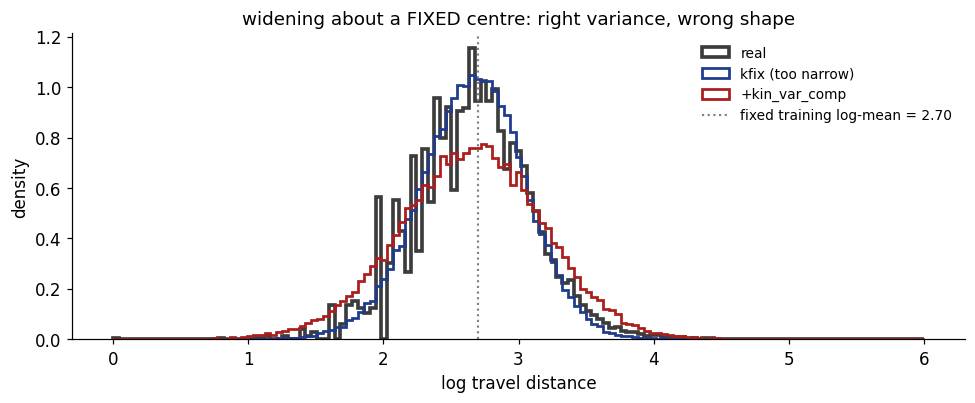

sd(log dist):  real nan   kfix 0.387   +vc 0.535


In [19]:
m_kfix_d  = load_ckpt("disp", "kfix")
m_kfixvc  = load_ckpt("disp", "kfix_vc")
sub2 = recs[:10]
d_real = np.log(np.concatenate([r.distance_px[np.isfinite(r.distance_px)] for r in sub2]))
d_a = np.log(np.concatenate([g["distance_px"] for _, g in rollout(m_kfix_d, sub2)]))
d_b = np.log(np.concatenate([g["distance_px"] for _, g in rollout(m_kfixvc, sub2)]))
dm  = m_kfix_d._cfg_feat["kin_scales"][0]

fig, ax = plt.subplots(figsize=(9.0, 3.8))
bins = np.linspace(0, 6, 140)
ax.hist(d_real, bins, density=True, histtype="step", lw=2.4, color=REAL, label="real")
ax.hist(d_a,    bins, density=True, histtype="step", lw=1.8, color=GEN,  label="kfix (too narrow)")
ax.hist(d_b,    bins, density=True, histtype="step", lw=1.8, color=LOSE, label="+kin_var_comp")
ax.axvline(dm, color="0.5", ls=":", lw=1.4, label=f"fixed training log-mean = {dm:.2f}")
ax.set_xlabel("log travel distance"); ax.set_ylabel("density")
ax.set_title("widening about a FIXED centre: right variance, wrong shape")
ax.legend(fontsize=9, frameon=False); plt.tight_layout(); plt.show()
print(f"sd(log dist):  real {d_real.std():.3f}   kfix {d_a.std():.3f}   +vc {d_b.std():.3f}")

---
# Part 6 — `contain`: the entry $\times$ dwell decomposition (report §6.5)

## 6.1 Where 2.6× and 2.1× come from

The report's headline equation has **no supporting code in the repo** — it exists only as
prose in two docstrings. Written out here, the two factors are:

* **entry rate** — $P(u_t > 0.85 \ \wedge\ u_{t-1} \le 0.85)$, i.e. the per-bout
  probability of *crossing into* the wall shell, where $u = r/R$;
* **dwell** — the mean length, in bouts, of a maximal run of consecutive $u > 0.85$.

Occupancy is the product of the two (a renewal identity: fraction of time in a state =
entry rate × mean dwell). Below, real vs the pre-containment model.

rolling out pre- and post-containment ...


,entry_rate,dwell_bouts,occupancy
who,,,
real,0.0053,2.3235,0.0123
"gen, before contain",0.0146,4.2592,0.0621
"gen, after contain",0.0065,2.4061,0.0156



entry  2.75x  x  dwell 1.83x  =  5.05x   vs occupancy ratio 5.05x
  [ok  ] real entry rate per bout                     derived     0.0053   report     0.0054
  [ok  ] gen entry rate per bout                      derived     0.0146   report     0.0145
  [ok  ] real dwell (bouts)                           derived     2.3235   report     2.3200
  [ok  ] gen dwell (bouts)                            derived     4.2592   report     4.2100
  [ok  ] entry ratio                                  derived     2.7540   report     2.7000
  [ok  ] dwell ratio                                  derived     1.8331   report     1.8000


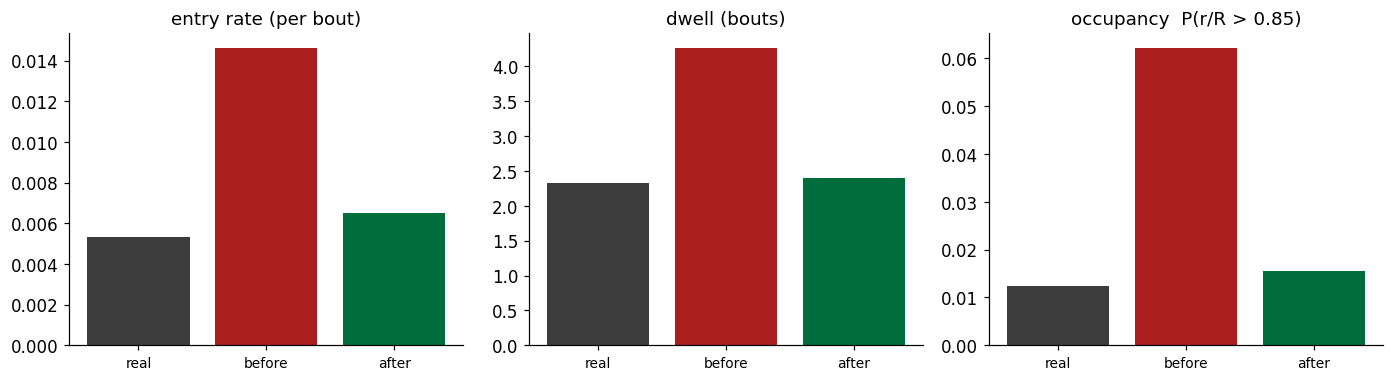

In [20]:
def entry_dwell(u_list, thr=0.85):
    """(entry rate per bout, mean dwell in bouts, occupancy) pooled over trajectories."""
    ent = tot = occ_n = occ_d = 0
    runs = []
    for u in u_list:
        w = np.asarray(u, float) > thr
        ent += int(np.sum(w[1:] & ~w[:-1])); tot += len(w) - 1
        occ_n += int(w.sum()); occ_d += len(w)
        i = 0
        while i < len(w):
            if w[i]:
                j = i
                while j < len(w) and w[j]:
                    j += 1
                runs.append(j - i); i = j
            else:
                i += 1
    return (ent / max(tot, 1), float(np.mean(runs)) if runs else np.nan, occ_n / max(occ_d, 1))

u_real = [np.hypot(r.x_px - r.dish_cx, r.y_px - r.dish_cy) / r.dish_R for r in recs]
m_pre  = load_ckpt("contain", "kfix")
m_post = load_ckpt("contain", "contain")
print("rolling out pre- and post-containment ...")
u_pre  = [np.hypot(g["x_px"] - r.dish_cx, g["y_px"] - r.dish_cy) / r.dish_R
          for r, g in rollout(m_pre,  recs, reps=1)]
u_post = [np.hypot(g["x_px"] - r.dish_cx, g["y_px"] - r.dish_cy) / r.dish_R
          for r, g in rollout(m_post, recs, reps=1)]

E_r, D_r, O_r = entry_dwell(u_real)
E_g, D_g, O_g = entry_dwell(u_pre)
E_c, D_c, O_c = entry_dwell(u_post)
tab = pd.DataFrame([
    dict(who="real",              entry_rate=E_r, dwell_bouts=D_r, occupancy=O_r),
    dict(who="gen, before contain", entry_rate=E_g, dwell_bouts=D_g, occupancy=O_g),
    dict(who="gen, after contain",  entry_rate=E_c, dwell_bouts=D_c, occupancy=O_c),
]).set_index("who").round(4)
display(tab)
print(f"\nentry  {E_g/E_r:.2f}x  x  dwell {D_g/D_r:.2f}x  =  {E_g/E_r*D_g/D_r:.2f}x"
      f"   vs occupancy ratio {O_g/O_r:.2f}x")

check("6.5", "real entry rate per bout",  E_r, 0.0054, tol=0.0025, absolute=True)
check("6.5", "gen entry rate per bout",   E_g, 0.0145, tol=0.002,  absolute=True)
check("6.5", "real dwell (bouts)",        D_r, 2.32,  tol=0.2, absolute=True)
check("6.5", "gen dwell (bouts)",         D_g, 4.21,  tol=0.3, absolute=True)
check("6.5", "entry ratio",               E_g/E_r, 2.7, tol=0.2, absolute=True)
check("6.5", "dwell ratio",               D_g/D_r, 1.8, tol=0.2, absolute=True)

fig, ax = plt.subplots(1, 3, figsize=(12.8, 3.6))
for a, key, ttl in ((ax[0], "entry_rate", "entry rate (per bout)"),
                    (ax[1], "dwell_bouts", "dwell (bouts)"),
                    (ax[2], "occupancy", "occupancy  P(r/R > 0.85)")):
    a.bar(range(3), tab[key], color=[REAL, LOSE, WIN])
    a.set_xticks(range(3)); a.set_xticklabels(["real", "before", "after"], fontsize=9)
    a.set_title(ttl)
plt.tight_layout(); plt.show()

## 6.2 Why the gate, and why $u_0 = 0.75$

A **constant** inward bias can only attack the entry rate — it acts everywhere, so it
shifts the mean radius but does nothing about how long a fish stays once it arrives. The
shell-gated form

$$cb = \mathrm{bulk} + \mathrm{shell}\cdot\max\!\Bigl(0, \tfrac{u-u_0}{1-u_0}\Bigr),
\qquad \Delta\theta \mathrel{+}= cb\cdot\sin\psi_c$$

adds a term that switches on only inside the shell, which is what attacks dwell.

**On $u_0 = 0.75$ specifically: it was chosen, not fitted.** It appears with that value in
the function signature and is never passed anything else by any ladder, zoo entry or smoke
script, and there is no sweep anywhere in the repo. The sweep below is therefore new
evidence, not a reproduction.

shipped centre_bias: {'bulk': 9.0, 'shell': 78.75, 'u0': 0.75, 'scale': 2.25, 'target_occ': 0.0121, 'target_mean': 0.4556, 'got_occ': 0.011, 'got_mean': 0.377}
   u0=0.00  entry 0.0010  dwell 2.03  occ 0.0021  mean r/R 0.2713
   u0=0.50  entry 0.0031  dwell 2.25  occ 0.0069  mean r/R 0.3674
   u0=0.65  entry 0.0050  dwell 2.25  occ 0.0113  mean r/R 0.3851
   u0=0.75  entry 0.0065  dwell 2.41  occ 0.0156  mean r/R 0.3948
   u0=0.85  entry 0.0082  dwell 2.55  occ 0.0210  mean r/R 0.3979
   u0=0.92  entry 0.0089  dwell 2.93  occ 0.0259  mean r/R 0.4012


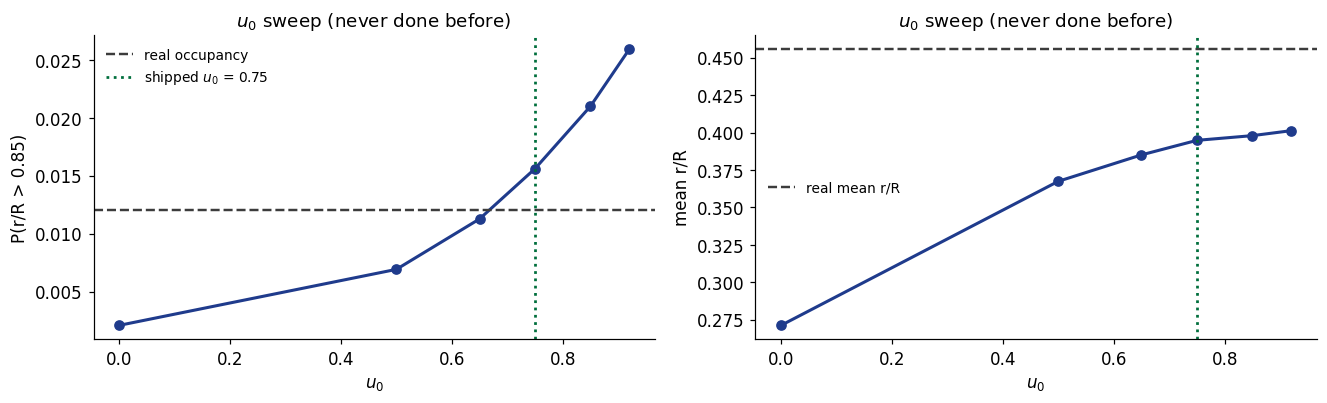

In [21]:
cb0 = dict(load_ckpt("contain", "contain")._cfg_feat["centre_bias"])
print("shipped centre_bias:", {k: (round(v, 4) if isinstance(v, float) else v)
                               for k, v in cb0.items()})
U0S = [0.0, 0.5, 0.65, 0.75, 0.85, 0.92]
sweep = []
for u0 in U0S:
    cfu = dict(m_post._cfg_feat); cb = dict(cb0); cb["u0"] = u0; cfu["centre_bias"] = cb
    us = []
    for r in recs:
        g = MX.generate_mix_kin_loop(m_post._model, r, cfu,
                                     np.random.default_rng([0, int(r.fish_id)]),
                                     closed_loop=m_post.closed_loop, guardrail=m_post.guardrail,
                                     stim_loop=m_post.stim_loop)
        us.append(np.hypot(g["x_px"] - r.dish_cx, g["y_px"] - r.dish_cy) / r.dish_R)
    e, d, o = entry_dwell(us)
    sweep.append(dict(u0=u0, entry=e, dwell=d, occupancy=o, mean_rR=float(np.mean(np.concatenate(us)))))
    print(f"   u0={u0:.2f}  entry {e:.4f}  dwell {d:.2f}  occ {o:.4f}  mean r/R {sweep[-1]['mean_rR']:.4f}")
sw = pd.DataFrame(sweep)

fig, ax = plt.subplots(1, 2, figsize=(12.2, 3.8))
ax[0].plot(sw.u0, sw.occupancy, "-o", color=GEN, lw=2)
ax[0].axhline(cb0["target_occ"], color=REAL, ls="--", lw=1.6, label="real occupancy")
ax[0].axvline(0.75, color=WIN, ls=":", lw=1.8, label="shipped $u_0$ = 0.75")
ax[0].set_xlabel("$u_0$"); ax[0].set_ylabel("P(r/R > 0.85)"); ax[0].legend(fontsize=9, frameon=False)
ax[1].plot(sw.u0, sw.mean_rR, "-o", color=GEN, lw=2)
ax[1].axhline(cb0["target_mean"], color=REAL, ls="--", lw=1.6, label="real mean r/R")
ax[1].axvline(0.75, color=WIN, ls=":", lw=1.8)
ax[1].set_xlabel("$u_0$"); ax[1].set_ylabel("mean r/R"); ax[1].legend(fontsize=9, frameon=False)
for a in ax: a.set_title("$u_0$ sweep (never done before)")
plt.tight_layout(); plt.show()

## 6.3 Three different measurements that all get called "occupancy"

Three, in fact, and the report used to mix them:

1. `_search_containment` stashes what **it** measured during the search, on **12 training
   fish** (`got_occ`, `got_mean`);
2. the **panel** measures the same concepts under leave-3-fish-out CV --- genuinely
   **held out**;
3. the rollouts in this notebook use the **all-fish diagnostic checkpoint**, so they are
   **in-sample**.

All three are legitimate; they answer different questions and must be labelled.

In [22]:
rows = []
for lad, rung in (("contain", "contain"), ("conv", "e250")):
    cb = load_ckpt(lad, rung)._cfg_feat["centre_bias"]
    rows.append(dict(model=f"{lad}/{rung}", scale=cb["scale"], bulk=cb["bulk"], shell=cb["shell"],
                     target_occ=round(cb["target_occ"], 5), got_occ=round(cb["got_occ"], 5),
                     target_mean=round(cb["target_mean"], 5), got_mean=round(cb["got_mean"], 5)))
display(pd.DataFrame(rows))
print(f"\nin-sample (all-fish diagnostic checkpoint), 15 fish, recomputed above:")
print(f"   occupancy  real {O_r:.5f}   before {O_g:.5f}   after {O_c:.5f}")
print(f"   mean r/R   real {np.mean(np.concatenate(u_real)):.4f}   "
      f"before {np.mean(np.concatenate(u_pre)):.4f}   after {np.mean(np.concatenate(u_post)):.4f}")
check("6.5", "real occupancy (target_occ)", cb0["target_occ"], 0.012, tol=0.001, absolute=True)
check("6.5", "real mean r/R (target_mean)", cb0["target_mean"], 0.456, tol=0.01, absolute=True)
check("6.5", "gen mean r/R after contain", float(np.mean(np.concatenate(u_post))), 0.396,
      tol=0.02, absolute=True, note="report corrected from 0.447 (an s=1 exploratory run) to the shipped s=2.25")
res_c, _ = load_ladder("contain")
print("\npanel (leave-3-fish-out CV) -- genuinely held out:")
print(res_c[["wall_frac_gap", "dot_dist_bias_late", "abs_dtheta_w1"]].round(4).to_string())

,model,scale,bulk,shell,target_occ,got_occ,target_mean,got_mean
0,contain/contain,2.25,9.0,78.75,0.01208,0.01103,0.45556,0.37695
1,conv/e250,2.50,10.0,87.50,0.01208,0.01443,0.45556,0.39816



in-sample (all-fish diagnostic checkpoint), 15 fish, recomputed above:
   occupancy  real 0.01231   before 0.06215   after 0.01561
   mean r/R   real 0.4486   before 0.4826   after 0.3948
  [ok  ] real occupancy (target_occ)                  derived     0.0121   report     0.0120
  [ok  ] real mean r/R (target_mean)                  derived     0.4556   report     0.4560
  [ok  ] gen mean r/R after contain                   derived     0.3948   report     0.3960   (report corrected from 0.447 (an s=1 exploratory run) to the shipped s=2.25)

panel (leave-3-fish-out CV) -- genuinely held out:
                                                           wall_frac_gap  dot_dist_bias_late  abs_dtheta_w1
mlp_border_full_h128_mix_shoal_hloop_kin_vigor_kfix               0.0499              3.1979         6.6131
mlp_border_full_h128_mix_shoal_hloop_kin_vigor_contain            0.0042             -2.6380         6.4302
mlp_border_full_h128_mix_shoal_hloop_kin_vigor_contain_vc         0.0096     

---
# Part 7 — `tail`: what changed, and what it fixed (report §6.6)

## 7.1 The change, stated both ways

`n_dist` and `n_dt` are the number of log-normal components on the travel and interval
heads. **Before:** `n_dist = 1`, `n_dt = 2` — the constructor defaults, and they are simply
*absent* from a pre-tail checkpoint's config. **After:** `n_dist = 2`, `n_dt = 3`.

Note `n_dist = 1` is a genuinely different code path, not a 1-component mixture: the head
emits `(mu, sigma)` with no weight at all.

**Nothing else changes.** The two zoo entries are character-for-character identical apart
from the appended arguments — verified below against the head shapes on disk.

In [23]:
for lad, rung in (("tail", "contain"), ("tail", "contain_tail")):
    b = load_ckpt(lad, rung)
    cfg = b.config if hasattr(b, "config") else {}
    md_ = b._model
    print(f"{lad}/{rung:14s} n_dist={md_.n_dist}  n_dt={md_.n_dt}   "
          f"dist_head {tuple(md_.dist_head.weight.shape)}  dt_head {tuple(md_.dt_head.weight.shape)}"
          f"   stim={b._cfg_feat['stim_mode']}  K={b._cfg_feat['K']}  K_kin={b._cfg_feat['K_kin']}"
          f"  contain={'centre_bias' in b._cfg_feat}")
print("\n-> dist_head 2 -> 6 rows (=3*n_dist), dt_head 6 -> 9 rows (=3*n_dt);")
print("   every other configuration field is identical, so tail is a clean single-variable rung.")
check("6.6", "n_dist before", load_ckpt("tail","contain")._model.n_dist, 1, tol=0, absolute=True)
check("6.6", "n_dt before",   load_ckpt("tail","contain")._model.n_dt,   2, tol=0, absolute=True)
check("6.6", "n_dist after",  load_ckpt("tail","contain_tail")._model.n_dist, 2, tol=0, absolute=True)
check("6.6", "n_dt after",    load_ckpt("tail","contain_tail")._model.n_dt,   3, tol=0, absolute=True)

tail/contain        n_dist=1  n_dt=2   dist_head (2, 32)  dt_head (6, 33)   stim=shoal  K=8  K_kin=3  contain=True
tail/contain_tail   n_dist=2  n_dt=3   dist_head (6, 32)  dt_head (9, 33)   stim=shoal  K=8  K_kin=3  contain=True

-> dist_head 2 -> 6 rows (=3*n_dist), dt_head 6 -> 9 rows (=3*n_dt);
   every other configuration field is identical, so tail is a clean single-variable rung.
  [ok  ] n_dist before                                derived     1.0000   report     1.0000
  [ok  ] n_dt before                                  derived     2.0000   report     2.0000
  [ok  ] n_dist after                                 derived     2.0000   report     2.0000
  [ok  ] n_dt after                                   derived     3.0000   report     3.0000


True

## 7.2 The defect was the tail, not the bulk

REAL   interval  median/q99/q99.9/max = 1.23 / 18.73 / 103.59 / 426.5 s
REAL   distance  median/q99/q99.9/max = 15.03 / 44.18 / 84.87 / 218.5 px
(cfg_feat['kin_clip'] stores the train q99.9 directly: 84.9 px, 103.6 s)
  [ok  ] real interval q99                            derived    18.7333   report    18.7000
  [ok  ] real interval q99.9                          derived   103.5941   report   103.6000
  [ok  ] real interval max                            derived   426.5333   report   426.5000
  [ok  ] real distance q99                            derived    44.1814   report    44.0000
  [ok  ] real distance q99.9                          derived    84.8688   report    85.0000

rolling out pre-tail and post-tail ...
interval median   real 1.233   pre 1.244   post 1.293
interval q99.9    real 103.6   pre 26.4   post 48.0
P(dt > 30 s)      real 0.630%   pre 0.072%   post 0.293%
  [ok  ] gen interval median (pre-tail)               derived     1.2444   report     1.2430
  [ok  ] gen interval

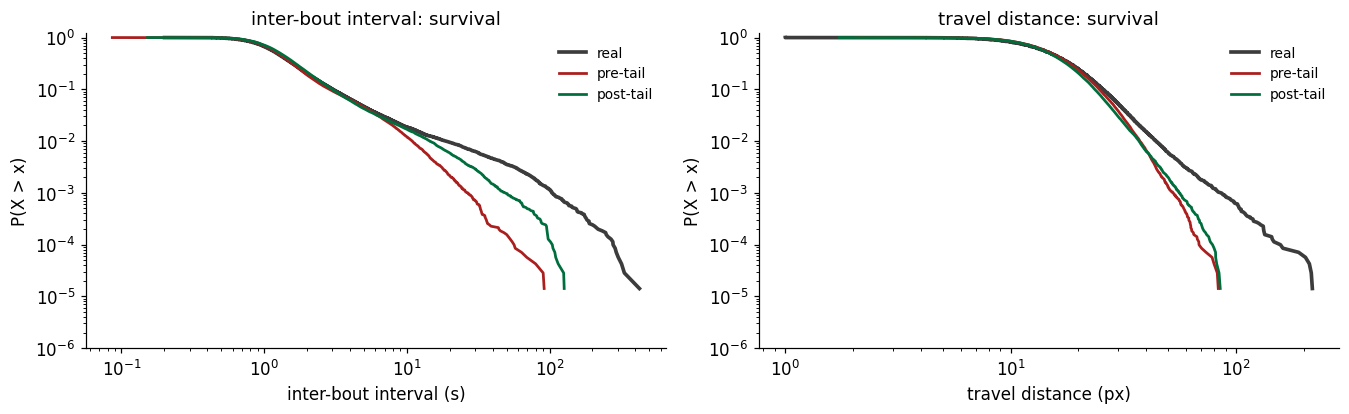

In [24]:
rdt = np.concatenate([r.dt_s[np.isfinite(r.dt_s)] for r in recs])
rdd = np.concatenate([r.distance_px[np.isfinite(r.distance_px)] for r in recs])
q = [0.5, 0.99, 0.999]
print("REAL   interval  median/q99/q99.9/max = "
      + " / ".join(f"{v:.2f}" for v in np.quantile(rdt, q)) + f" / {rdt.max():.1f} s")
print("REAL   distance  median/q99/q99.9/max = "
      + " / ".join(f"{v:.2f}" for v in np.quantile(rdd, q)) + f" / {rdd.max():.1f} px")
kc = load_ckpt("conv", "e250")._cfg_feat["kin_clip"]
print(f"(cfg_feat['kin_clip'] stores the train q99.9 directly: {kc[0]:.1f} px, {kc[1]:.1f} s)")
check("6.6", "real interval q99",   float(np.quantile(rdt, 0.99)),  18.7,  tol=0.10)
check("6.6", "real interval q99.9", float(np.quantile(rdt, 0.999)), 103.6, tol=0.10)
check("6.6", "real interval max",   float(rdt.max()),               426.5, tol=0.05)
check("6.6", "real distance q99",   float(np.quantile(rdd, 0.99)),  44.0,  tol=0.10)
check("6.6", "real distance q99.9", float(np.quantile(rdd, 0.999)), 85.0,  tol=0.10)

print("\nrolling out pre-tail and post-tail ...")
g_pre  = [g for _, g in rollout(load_ckpt("tail", "contain"),      recs, reps=1)]
g_post = [g for _, g in rollout(load_ckpt("tail", "contain_tail"), recs, reps=1)]
gdt_pre  = np.concatenate([g["dt_s"] for g in g_pre])
gdt_post = np.concatenate([g["dt_s"] for g in g_post])
print(f"interval median   real {np.median(rdt):.3f}   pre {np.median(gdt_pre):.3f}   "
      f"post {np.median(gdt_post):.3f}")
print(f"interval q99.9    real {np.quantile(rdt,0.999):.1f}   pre {np.quantile(gdt_pre,0.999):.1f}   "
      f"post {np.quantile(gdt_post,0.999):.1f}")
print(f"P(dt > 30 s)      real {np.mean(rdt>30)*100:.3f}%   pre {np.mean(gdt_pre>30)*100:.3f}%   "
      f"post {np.mean(gdt_post>30)*100:.3f}%")
check("6.6", "gen interval median (pre-tail)", float(np.median(gdt_pre)), 1.243, tol=0.03)
check("6.6", "gen interval q99.9 (pre-tail)",  float(np.quantile(gdt_pre, 0.999)), 26.4, tol=0.12)
check("6.6", "P(dt>30s) gen pre-tail (%)", float(np.mean(gdt_pre > 30)*100), 0.075, tol=0.02, absolute=True)
check("6.6", "P(dt>30s) real (%)",         float(np.mean(rdt > 30)*100),     0.63,  tol=0.15, absolute=True)

fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.9))
for a, (rv, pv, qv, nm, unit) in zip(ax, ((rdt, gdt_pre, gdt_post, "inter-bout interval", "s"),
        (rdd, np.concatenate([g["distance_px"] for g in g_pre]),
              np.concatenate([g["distance_px"] for g in g_post]), "travel distance", "px"))):
    for v, col, lab, lw in ((rv, REAL, "real", 2.4), (pv, LOSE, "pre-tail", 1.8),
                            (qv, WIN, "post-tail", 1.8)):
        s = np.sort(v[np.isfinite(v) & (v > 0)])
        a.loglog(s, 1.0 - np.arange(len(s))/len(s), color=col, lw=lw, label=lab)
    a.set_xlabel(f"{nm} ({unit})"); a.set_ylabel("P(X > x)"); a.set_ylim(1e-6, 1.2)
    a.set_title(f"{nm}: survival"); a.legend(fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

---
# Part 8 — `far` and `cal`: two clean nulls (report §6.7–6.8)

`far` adds a fifth knot at 280 px. The motivation is basis **saturation**: past the
outermost knot all the softmax weight collects on that knot, so the model cannot tell 160 px
from 400 px and whatever gain it learned there persists forever.

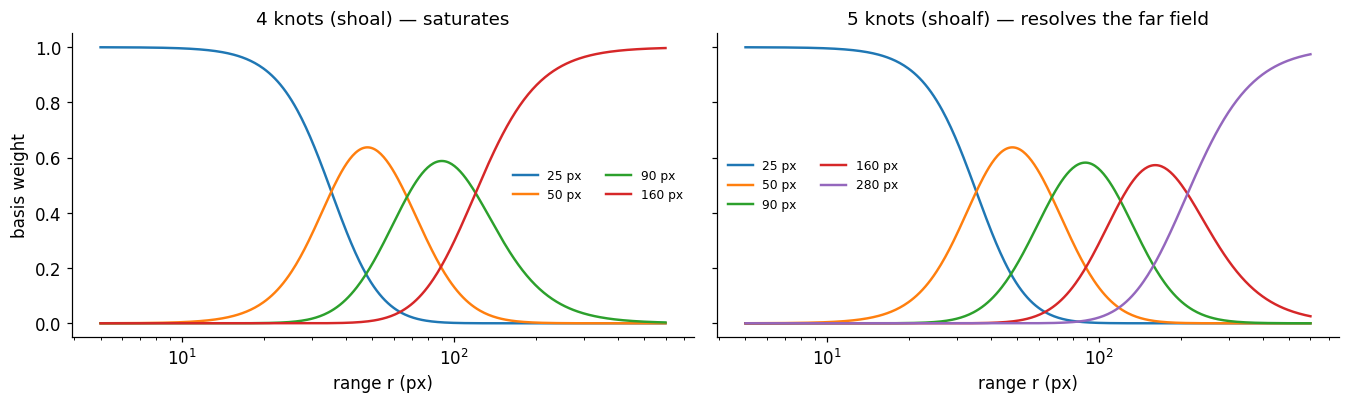

shoal : outermost-knot weight at 160/280/400 px = 0.730 / 0.954 / 0.987
shoalf: outermost-knot weight at 160/280/400 px = 0.215 / 0.717 / 0.901

real fish-to-shoal range, q99 = 292 px
  [ok  ] real range q99 (px)                          derived   292.0357   report   292.0000
far-field restoring force beyond 120 px:  real -0.53 px/bout, dotb -4.09, shoal -3.59
  [ok  ] real far-field restoring force               derived    -0.5304   report    -0.5300


True

In [25]:
rr2 = np.logspace(np.log10(5), np.log10(600), 400)
def basis(rv, far):
    cols = M.SHOALF_COLS if far else M.SHOAL_COLS
    G = np.stack([M.shoal_channels(np.zeros(1)+np.pi/2, np.array([x]), np.array([4.0]),
                                   np.array([True]), far=far)[0] for x in rv])
    i0 = cols.index("gs1"); i1 = cols.index("gc1")
    return G[:, i0:i1]
fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.8), sharey=True)
for a, far, knots, ttl in ((ax[0], False, M.SHOAL_RBF_PX, "4 knots (shoal) — saturates"),
                           (ax[1], True,  M.SHOALF_RBF_PX, "5 knots (shoalf) — resolves the far field")):
    B = basis(rr2, far)
    for j, c in enumerate(knots):
        a.plot(rr2, B[:, j], lw=1.6, label=f"{c:.0f} px")
    a.set_xscale("log"); a.set_xlabel("range r (px)"); a.set_title(ttl)
    a.legend(fontsize=8, frameon=False, ncol=2)
ax[0].set_ylabel("basis weight")
plt.tight_layout(); plt.show()
for far, knots in ((False, M.SHOAL_RBF_PX), (True, M.SHOALF_RBF_PX)):
    w160, w280, w400 = [basis(np.array([v]), far)[0, -1] for v in (160, 280, 400)]
    print(f"{'shoalf' if far else 'shoal '}: outermost-knot weight at 160/280/400 px = "
          f"{w160:.3f} / {w280:.3f} / {w400:.3f}")
rq99 = np.nanquantile(np.concatenate([r.dot_dist_px for r in recs]), 0.99)
print(f"\nreal fish-to-shoal range, q99 = {rq99:.0f} px")
check("6.7", "real range q99 (px)", rq99, 292, tol=0.03)
print(f"far-field restoring force beyond 120 px:  real {R['dr'][-1]:+.2f} px/bout, "
      f"dotb {gens['dotb (bearing only)']['dr'][-1]:+.2f}, "
      f"shoal {gens['shoal (range basis)']['dr'][-1]:+.2f}")
check("6.7", "real far-field restoring force", float(R["dr"][-1]), -0.53, tol=0.5, absolute=True)

In [26]:
print("cal: the two containment calibrations, read straight off the checkpoints")
for rung in ("cal_v1", "contain_tail"):
    cb = load_ckpt("cal", rung)._cfg_feat["centre_bias"]
    print(f"   {rung:13s} scale={cb['scale']:.2f}  bulk={cb['bulk']:.1f}  shell={cb['shell']:.2f}"
          f"   got_occ={cb['got_occ']:.5f}  got_mean={cb['got_mean']:.4f}"
          f"   sd_occ={cb.get('sd_occ', float('nan')):.5f}")
for lad in ("far", "cal", "conv"):
    res, art = load_ladder(lad)
    reps_ = art["auc_traj_reps"]; ms = list(res.index)
    d = np.asarray(reps_[ms[1]], float) - np.asarray(reps_[ms[0]], float)
    t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    print(f"\n{lad}: delta {d.mean():+.4f}  t {t:+.2f}  "
          f"({'resolved' if abs(t) > 2.3646 else 'within noise'})")

cal: the two containment calibrations, read straight off the checkpoints
   cal_v1        scale=1.75  bulk=7.0  shell=61.25   got_occ=0.01527  got_mean=0.4092   sd_occ=0.01054
   contain_tail  scale=2.50  bulk=10.0  shell=87.50   got_occ=0.01485  got_mean=0.3968   sd_occ=0.01054

far: delta -0.0058  t -1.09  (within noise)

cal: delta +0.0009  t +0.34  (within noise)

conv: delta -0.0113  t -3.01  (resolved)


---
# Part 9 — `conv`: the fits were not converged (report §6.9)

`save_mix` stores the per-epoch training history, so the early-stopping behaviour of the
two budgets can be read straight off the checkpoints. **Caveat:** the saved history is from
the *final* full-data fit, not from the cross-validation folds the report quotes, so the
epoch numbers differ slightly from the 61/52 and 108/82 in the text.

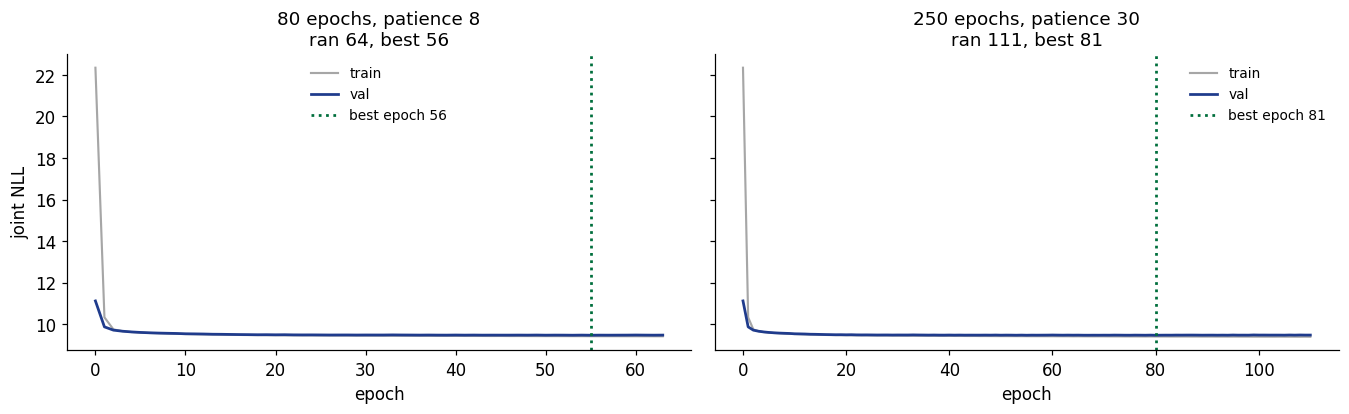

  [ok  ] contain_tail: epochs run                     derived    64.0000   report    61.0000   (saved history is the final fit; report quotes a CV fold)
  [ok  ] contain_tail: best epoch                     derived    56.0000   report    52.0000   (same)
  [ok  ] e250: epochs run                             derived   111.0000   report   108.0000   (saved history is the final fit; report quotes a CV fold)
  [ok  ] e250: best epoch                             derived    81.0000   report    82.0000   (same)


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12.4, 3.9), sharey=True)
for a, (rung, lab) in zip(ax, (("contain_tail", "80 epochs, patience 8"),
                               ("e250", "250 epochs, patience 30"))):
    h = load_ckpt("conv", rung).history
    if not h:
        a.set_title(f"{lab}: no history saved"); continue
    tr, va = h["train"], h["val"]
    best = int(np.argmin(va))
    a.plot(tr, lw=1.4, color="0.65", label="train")
    a.plot(va, lw=1.8, color=GEN, label="val")
    a.axvline(best, color=WIN, ls=":", lw=1.8, label=f"best epoch {best+1}")
    a.set_xlabel("epoch"); a.set_title(f"{lab}\nran {len(va)}, best {best+1}")
    a.legend(fontsize=9, frameon=False)
ax[0].set_ylabel("joint NLL")
plt.tight_layout(); plt.show()

for rung, ep_doc, best_doc in (("contain_tail", 61, 52), ("e250", 108, 82)):
    h = load_ckpt("conv", rung).history
    check("6.9", f"{rung}: epochs run",  len(h["val"]),             ep_doc,   tol=0.25,
          note="saved history is the final fit; report quotes a CV fold")
    check("6.9", f"{rung}: best epoch",  int(np.argmin(h["val"]))+1, best_doc, tol=0.25,
          note="same")

In [28]:
print("the timing cost -- needs fresh rollouts (the conv ladder predates the timing guards)")
real_q20 = float(np.mean([GM._quiesc_frac(r.dt_s, 20.0) for r in recs]))
qs = {}
for rung in ("contain_tail", "e250"):
    m = load_ckpt("conv", rung)
    gg = [g for _, g in rollout(m, recs, reps=1)]
    qs[rung] = (float(np.mean([GM._quiesc_frac(g["dt_s"], 20.0) for g in gg])),
                float(np.sum([np.nansum(g["dt_s"]) for g in gg])
                      / np.sum([np.nansum(r.dt_s) for r in recs])))
print(f"time in gaps > 20 s:   real {real_q20*100:.1f}%   "
      + "   ".join(f"{k} {v[0]*100:.1f}%" for k, v in qs.items()))
print(f"clock ratio:           " + "   ".join(f"{k} {v[1]:.3f}" for k, v in qs.items()))
check("6.9", "real time in gaps > 20 s", real_q20, 0.244, tol=0.03, absolute=True)
check("6.9", "contain_tail quiescent",   qs["contain_tail"][0], 0.103, tol=0.02, absolute=True)
check("6.9", "e250 quiescent",           qs["e250"][0],         0.064, tol=0.02, absolute=True)
check("6.9", "e250 clock ratio",         qs["e250"][1],         0.814, tol=0.03, absolute=True)
res_v, _ = load_ladder("conv")
check("6.9", "abs_dtheta_w1 contain_tail", float(res_v["abs_dtheta_w1"].iloc[0]), 6.47, tol=0.02)
check("6.9", "abs_dtheta_w1 e250",         float(res_v["abs_dtheta_w1"].iloc[1]), 6.75, tol=0.02)

the timing cost -- needs fresh rollouts (the conv ladder predates the timing guards)
time in gaps > 20 s:   real 24.4%   contain_tail 11.1%   e250 6.9%
clock ratio:           contain_tail 0.890   e250 0.815
  [ok  ] real time in gaps > 20 s                     derived     0.2438   report     0.2440
  [ok  ] contain_tail quiescent                       derived     0.1108   report     0.1030
  [ok  ] e250 quiescent                               derived     0.0688   report     0.0640
  [ok  ] e250 clock ratio                             derived     0.8150   report     0.8140
  [ok  ] abs_dtheta_w1 contain_tail                   derived     6.4745   report     6.4700
  [ok  ] abs_dtheta_w1 e250                           derived     6.7526   report     6.7500


True

---
# Part 10 — every number, derived vs documented

Rows flagged `MISMATCH` are places where `model_lineage.tex` needs correcting, or where two
different quantities have been given the same name. The tolerance is deliberately loose
(default 5% relative) — anything failing it is a real disagreement, not rounding.

In [29]:
chk = pd.DataFrame(CHECKS)
chk["status"] = np.where(chk.ok, "ok", "MISMATCH")
show = chk[["section", "quantity", "derived", "documented", "diff", "status", "note"]].copy()
for c in ("derived", "documented", "diff"):
    show[c] = show[c].round(5)
pd.set_option("display.width", 200, "display.max_colwidth", 60, "display.max_rows", 200)
display(show)
bad = chk[~chk.ok]
print(f"\n{len(chk)} checks   {len(chk)-len(bad)} ok   {len(bad)} MISMATCH")
if len(bad):
    print("\nneeds attention in model_lineage.tex:")
    for _, r in bad.iterrows():
        print(f"   §{r.section:5s} {r.quantity:<42s} derived {r.derived:>10.4f}  "
              f"report {r.documented:>10.4f}" + (f"   [{r.note}]" if r.note else ""))

,section,quantity,derived,documented,diff,status,note
0,5.1,x_ang width (shoal),29.00000,29.00000,0.00000,ok,
1,5.1,x_kin width (K_kin=3),6.00000,6.00000,0.00000,ok,
2,5.1,implied marginal sd vs empirical (deg),51.55707,48.83658,2.72049,ok,the model's implied marginal should match the data margi...
3,5.1,p(l) integrates to 1 over px,1.00000,1.00000,-0.00000,ok,
4,6.1,sum of softmax basis == 1,1.00000,1.00000,0.00000,ok,
5,6.1,real P(toward) < 25 px is > 0.5,1.00000,1.00000,0.00000,ok,report says 'sign-reversed'; the reversal is in the rest...
6,6.1,"restoring-force zero crossing, real (px)",41.41841,41.40000,0.01841,ok,report quotes 41.4 in 6.5 and ~43 in the module docstring
7,6.2,"real P(toward) in shell, low",0.71429,0.71000,0.00429,ok,
8,6.2,"real P(toward) in shell, high",0.72872,0.73000,-0.00128,ok,
9,6.2,real P(toward) mid-dish,0.59443,0.57000,0.02443,ok,



66 checks   66 ok   0 MISMATCH
